Imports

In [1]:
import numpy as np
import pandas as pd
import os
import re
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from tqdm import tqdm
import pickle
from torchvision.io import encode_png, encode_jpeg, decode_png, decode_jpeg
from scipy.fftpack import dct
from scipy.spatial.distance import cdist

/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
import torch.utils.data

import sys
sys.path.append('../..')
import random
from domainbed import datasets
from domainbed.lib import misc
from domainbed.location import find_algorithms, info_algorithms
from domainbed import algorithms
from domainbed.lib.fast_data_loader import InfiniteDataLoader, FastDataLoader, DataParallelPassthrough
from domainbed import hparams_registry

Initialize paths, read csvs

In [3]:
input_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/bestmultiruns/analysis"

# Csv files created in 'Save large csvs' section of shapley_results.ipynb
ALL_HP_CSV_PATH = os.path.join(input_dir, "all_hp.csv")
ALL_RES_CSV_PATH = os.path.join(input_dir, "all_res.csv")
BEST_HP_CSV_PATH = os.path.join(input_dir, "best_hp.csv")

In [4]:
# df_all_res = pd.read_csv(ALL_RES_CSV_PATH)
df_all_hp  = pd.read_csv(ALL_HP_CSV_PATH)
df_best_hp = pd.read_csv(BEST_HP_CSV_PATH)

# some HP config, not best
# df_best_hp = df_all_hp.sort_values(by=['alpha', 'gamma', 'beta', 'theta'], ascending=True).drop_duplicates(subset=['dataset', 'test_env', 'backbone', 'tta', 'find_algo'], keep='first')

In [5]:
df_best_hp['tta_acc'] = df_best_hp['tta_acc']*100
df_all_hp['tta_acc'] = df_all_hp['tta_acc']*100

In [6]:
for glist, df_group in df_all_hp[df_all_hp['find_algo'] == 'none'].groupby(['backbone', 'dataset', 'test_env', 'tta']):
    if len(set(df_group['tta_acc'].values)) != 1:
        display(df_group)
    # break

### Trainable blocks: performance distribution and heatmap plots

In [7]:
def get_polyfit_coeffs(xdata, ydata, degree=2):
    # weight = (ydata - ydata.min()) / (ydata.max() - ydata.min())
    # weight = None
    dist_from_max = np.abs(np.arange(len(ydata)) - ydata.argmax())
    weight = dist_from_max.max() - dist_from_max
    weight = np.exp(weight)
    weight = weight / weight.sum()

    # Fit a 2-degree polynomial
    coefficients = np.polyfit(xdata, ydata, degree, w=weight)
    return coefficients

def get_critical_point(xdata, ydata, degree=2):
    # Fit a 2-degree polynomial
    coefficients = get_polyfit_coeffs(xdata, ydata, degree=degree)

    # Calculate the derivative coefficients
    derivative_coefficients = np.polyder(coefficients)

    # Calculate the second derivative coefficients
    second_derivative_coefficients = np.polyder(derivative_coefficients)

    # Find the critical points (where the derivative equals zero)
    critical_points = np.roots(derivative_coefficients)

    # Keep only the roots that are real numbers between 1 and 4
    critical_points = critical_points[np.isreal(critical_points)]
    critical_points = np.clip(critical_points, xdata.min(), xdata.max())

    # Evaluate the polynomial at the critical points
    critical_values = np.polyval(coefficients, critical_points)

    # Find the location of maximum value
    critical_point = critical_points[critical_values.argmax()] = critical_points[critical_values.argmax()]

    # Evaluate the second derivative at the critical point
    second_derivative_value = np.polyval(second_derivative_coefficients, critical_point)

    if second_derivative_value > 0:
        critical_point = ydata.argmax()
    
    x_curve = np.linspace(xdata.min(), xdata.max(), 100)

    # Calculate corresponding y-values using the polynomial coefficients
    y_curve = np.polyval(coefficients, x_curve)

    return x_curve, y_curve, critical_point

def shiftedColorMap(cmap, data, start=0, stop=1.0, name='shiftedcmap'):
    '''
    Function to offset the "center" of a colormap. Useful for
    data with a negative min and positive max and you want the
    middle of the colormap's dynamic range to be at zero.

    Input
    -----
      cmap : The matplotlib colormap to be altered
      data : numpy ndimensional array to compute the midpoint from
      start : Offset from lowest point in the colormap's range.
          Defaults to 0.0 (no lower offset). Should be between
          0.0 and `midpoint`.
      stop : Offset from highest point in the colormap's range.
          Defaults to 1.0 (no upper offset). Should be between
          `midpoint` and 1.0.
    '''
    vmin = np.min(data)
    vmax = np.max(data)
    midpoint = 1 - vmax / (vmax + abs(vmin))

    cdict = {
        'red': [],
        'green': [],
        'blue': [],
        'alpha': []
    }

    # regular index to compute the colors
    reg_index = np.linspace(start, stop, 257)

    # shifted index to match the data
    shift_index = np.hstack([
        np.linspace(0.0, midpoint, 128, endpoint=False), 
        np.linspace(midpoint, 1.0, 129, endpoint=True)
    ])

    for ri, si in zip(reg_index, shift_index):
        r, g, b, a = cmap(ri)

        cdict['red'].append((si, r, r))
        cdict['green'].append((si, g, g))
        cdict['blue'].append((si, b, b))
        cdict['alpha'].append((si, a, a))

    newcmap = matplotlib.colors.LinearSegmentedColormap(name, cdict)
    
    # Check if a colormap with the same name is already registered
    if name in plt.colormaps():
        # If so, deregister it
        matplotlib.cm.unregister_cmap(name)
    
    # Register the new colormap
    matplotlib.cm.register_cmap(name, newcmap)

    return newcmap

In [8]:
# # layer_list = ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier']
# # layer_list = ['layer0', 'layer1', 'layer2', 'layer3', 'layer4']
# layer_list = ['layer1', 'layer2', 'layer3', 'layer4']
# perf_imprv_list = []
# gname_list = []
# critical_point_list = []
# # for idx, (glist, df_group) in enumerate(df_best_hp.groupby(['backbone', 'dataset', 'test_env', 'tta'])):
# # for idx, (glist, df_group) in enumerate(df_best_hp.groupby(['dataset', 'test_env'])):
# for idx, (glist, df_group) in enumerate(df_best_hp.groupby(['tta'])):
#     temp_list = []
#     for layer_subset in layer_list + ['none']:
#         temp_dict = {}
#         temp_dict['layer_subset'] = layer_subset
#         temp_dict['tta_acc'] = df_group[(df_group['find_algo'] == layer_subset)]['tta_acc'].mean()
#         temp_list.append(temp_dict)

#     df_temp = pd.DataFrame(temp_list)
#     df_temp['tta_acc'] = df_temp['tta_acc'] - df_temp[df_temp['layer_subset'] == 'none']['tta_acc'].values[0]
#     df_temp.drop(df_temp[df_temp['layer_subset'] == 'none'].index, inplace=True)

#     # Perform min-max normalization
#     df_temp['tta_acc'] = (df_temp['tta_acc'] - df_temp['tta_acc'].min()) / (df_temp['tta_acc'].max() - df_temp['tta_acc'].min())

#     this_perf_imprv = df_temp['tta_acc'].values
#     perf_imprv_list.append(this_perf_imprv)
#     gname_list.append(glist)

#     xdata = np.arange(len(layer_list))
#     ydata = this_perf_imprv
#     x_curve, y_curve, critical_point = get_critical_point(xdata, ydata, degree=2)
#     critical_point_list.append(critical_point)

#     # plt.figure(figsize=(10, 5))
#     # plt.bar(xdata, ydata)
#     # plt.plot(x_curve, y_curve, c='k')
#     # plt.axvline(x=critical_point, color='r', linestyle='--')
#     # plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
#     # plt.title(glist)
#     # plt.xlabel("Layer subset")
#     # plt.ylabel("Performance improvement")
#     # plt.xticks(xdata, layer_list)
#     # plt.show()

#     # if idx >= 3:
#     #     break

# perf_imprvs = np.array(perf_imprv_list)
# critical_points = np.array(critical_point_list)

# # argmax_idxs = np.argmax(perf_imprvs, axis=1)
# # sorted_idxs = np.argsort(argmax_idxs)
# # sorted_idxs = np.argsort(critical_points)
# sorted_idxs = [1, 0]

# sorted_perf_imprvs = perf_imprvs[sorted_idxs]
# sorted_gnames = [gname_list[i] for i in sorted_idxs]

# plt.figure(figsize=(5, 10))
# plt.imshow(sorted_perf_imprvs, cmap='viridis', origin='lower', aspect='auto')
# cbar = plt.colorbar()
# cbar.set_ticks([0, 1])
# cbar.set_ticklabels(['Barely Trainable', 'Highly Trainable'])

# # print gname_list in the same order as the sorted perf_imprvs on the plot
# plt.yticks(np.arange(len(sorted_gnames)), sorted_gnames)
# plt.xticks(np.arange(len(layer_list)), ['Block 1', 'Block 2', 'Block 3', 'Block 4'])

# plt.xlabel("Block number")
# plt.ylabel("tta")
# plt.title("Performance improvement (tta)")


Filter by: resnet18-BN+PseudoLabel


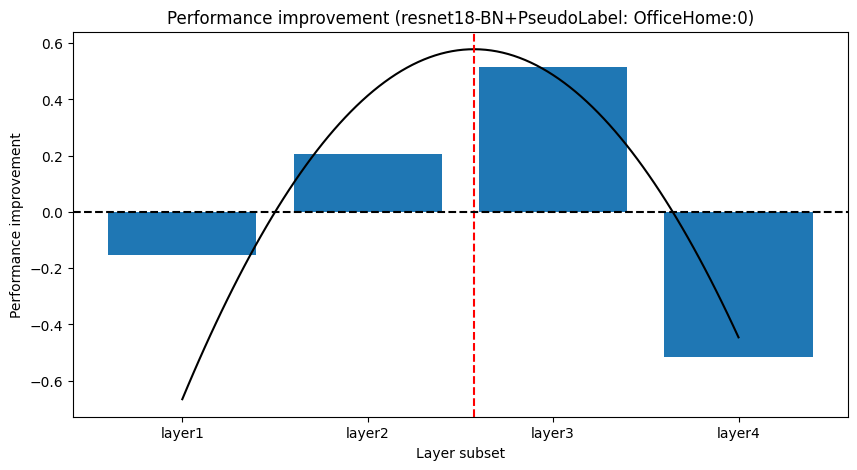

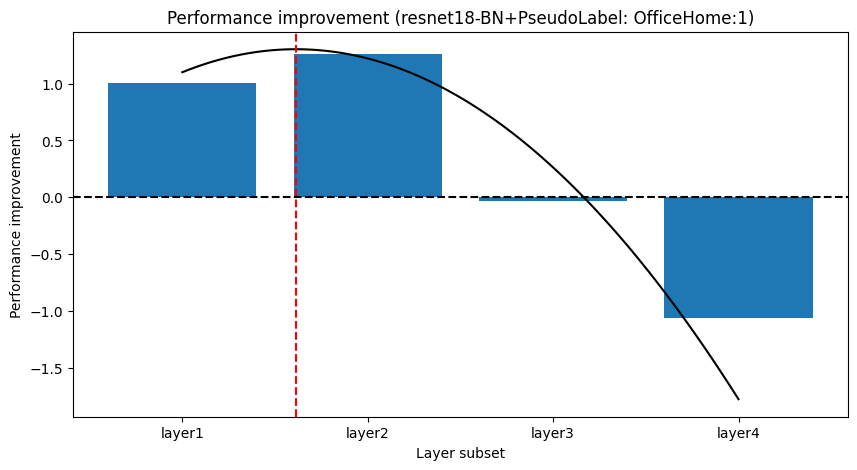

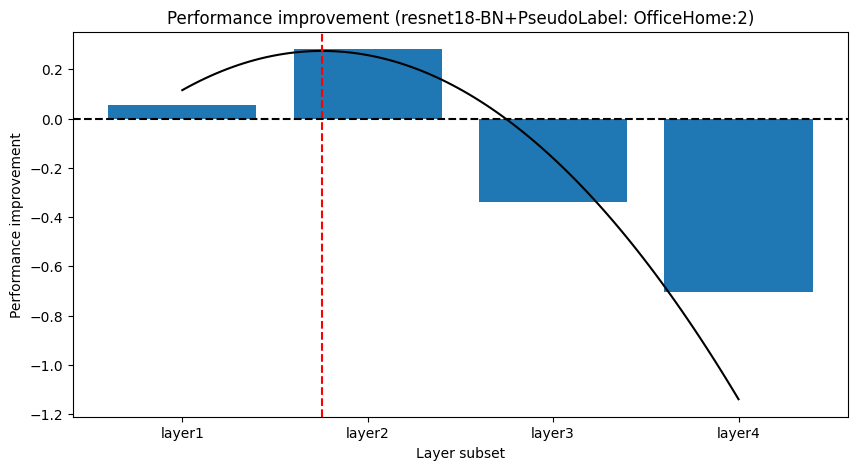

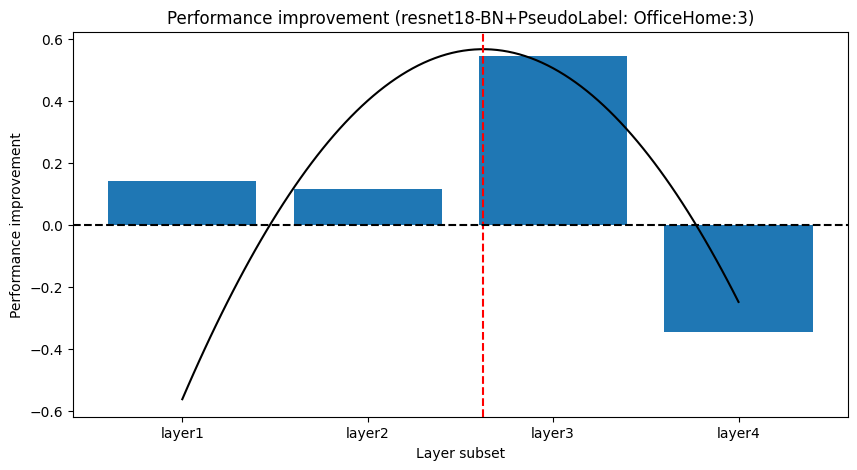

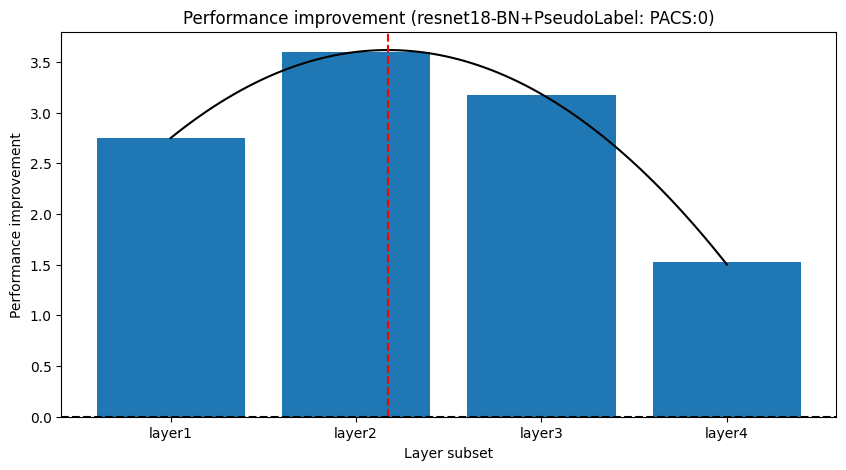

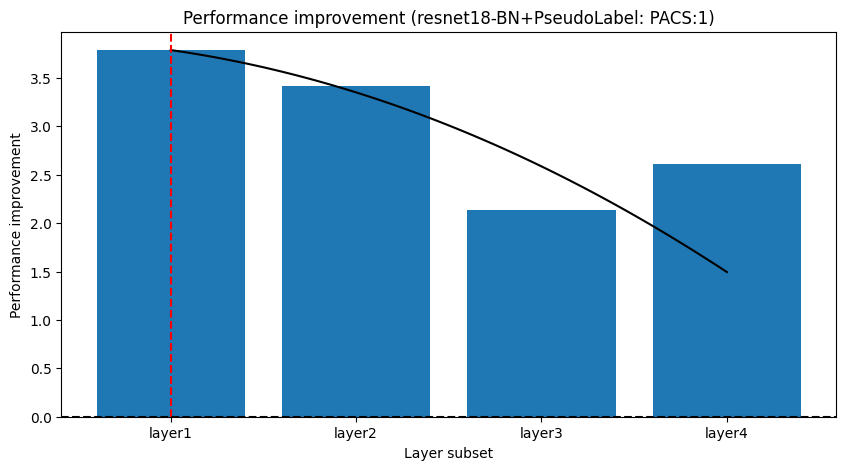

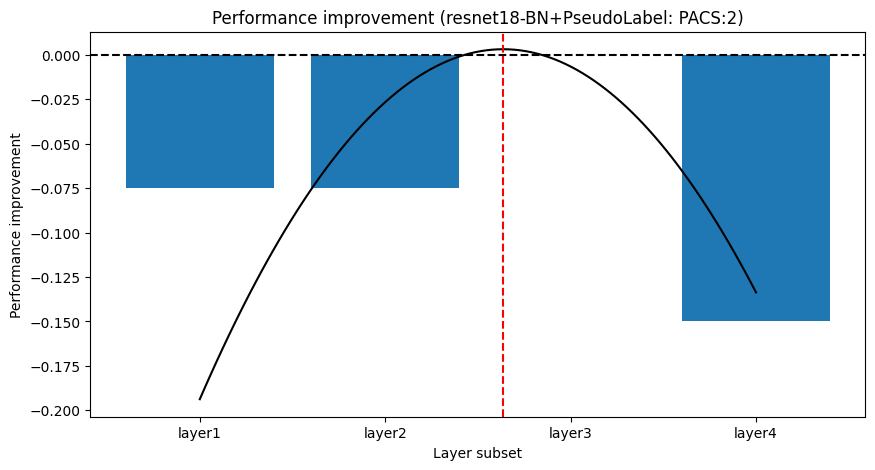

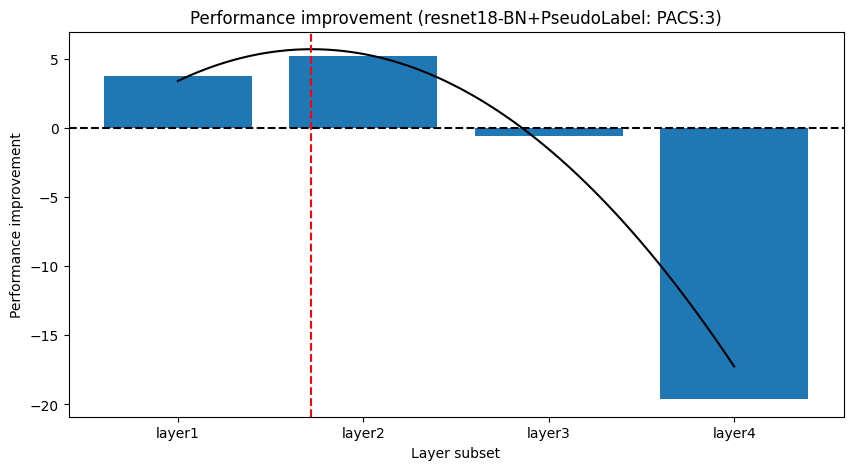

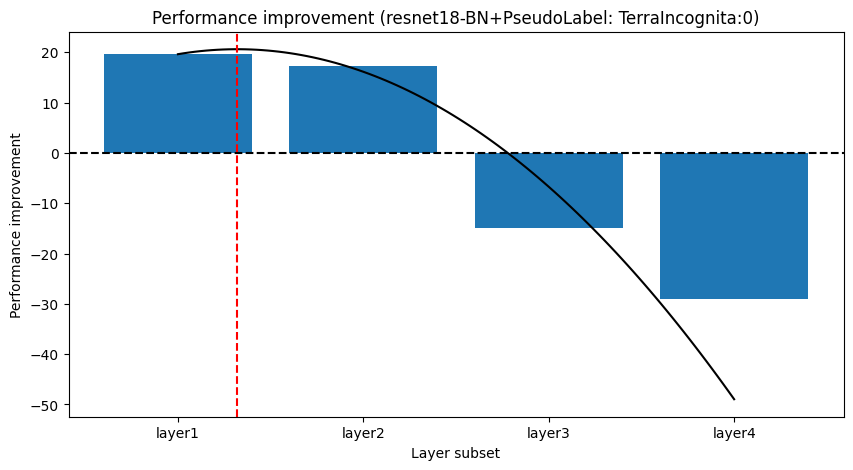

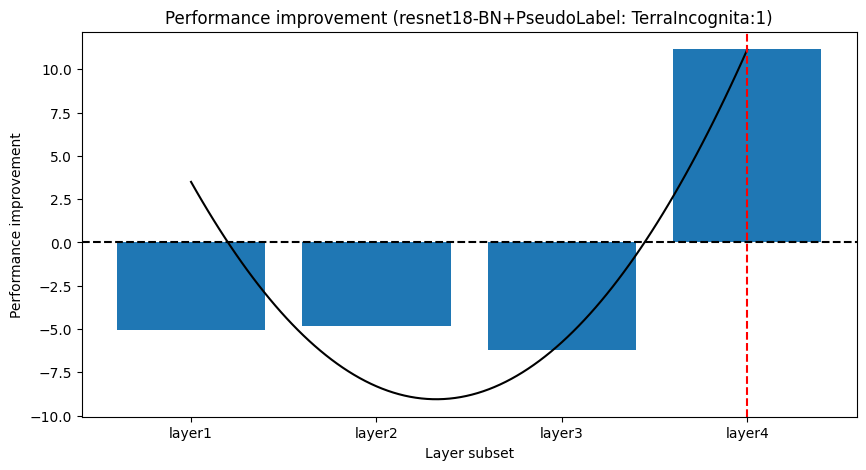

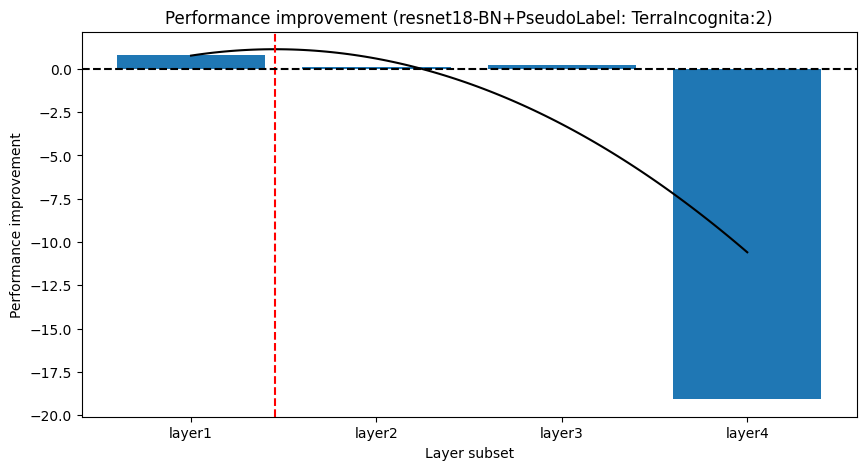

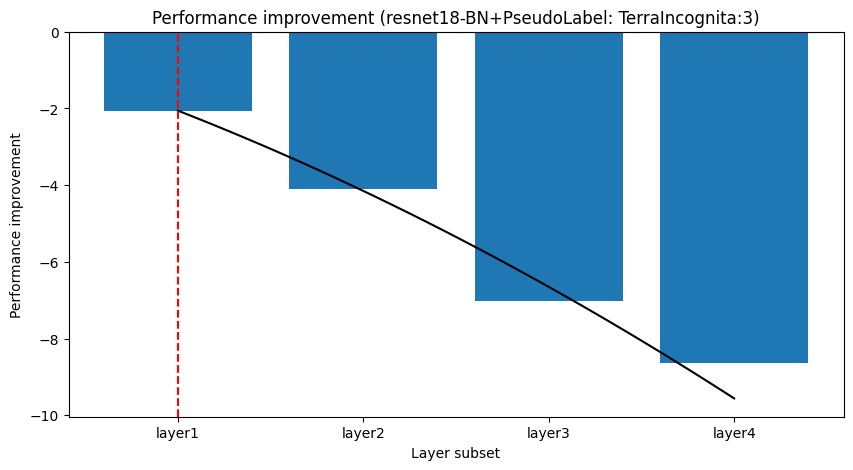

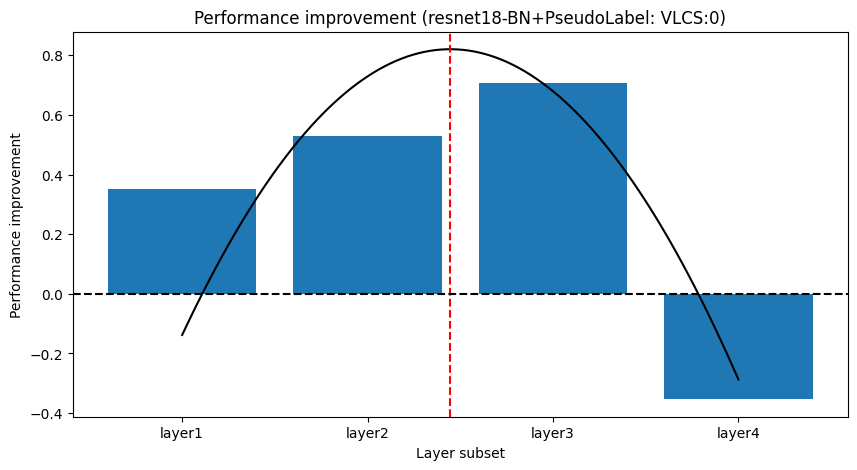

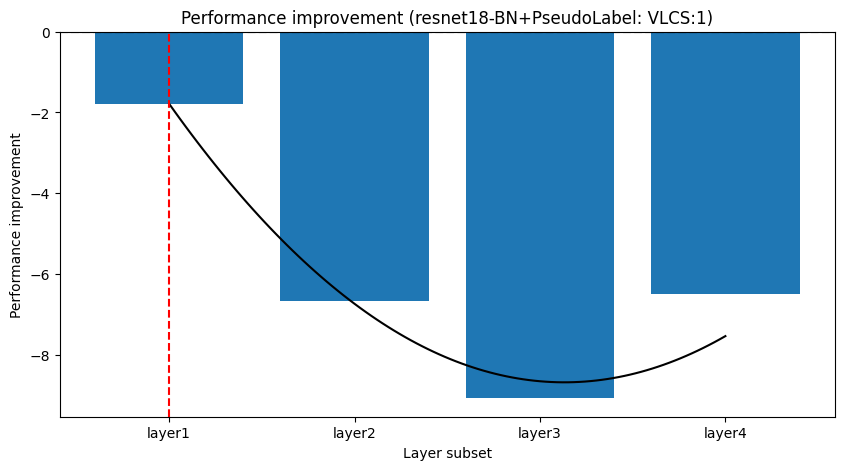

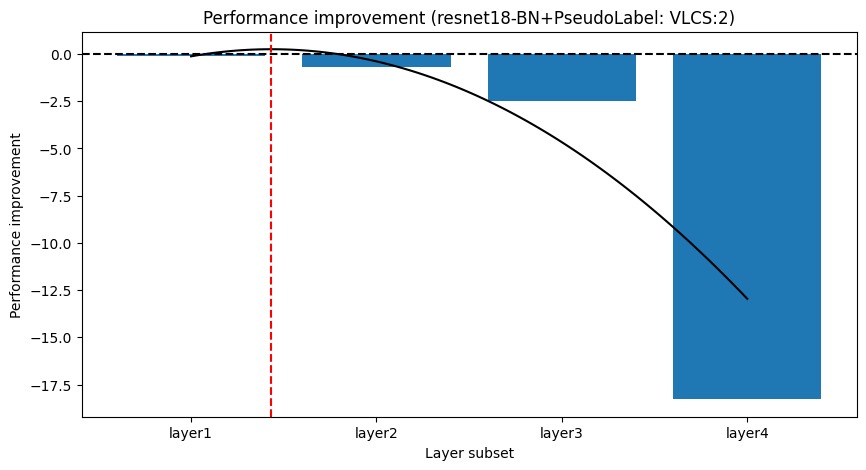

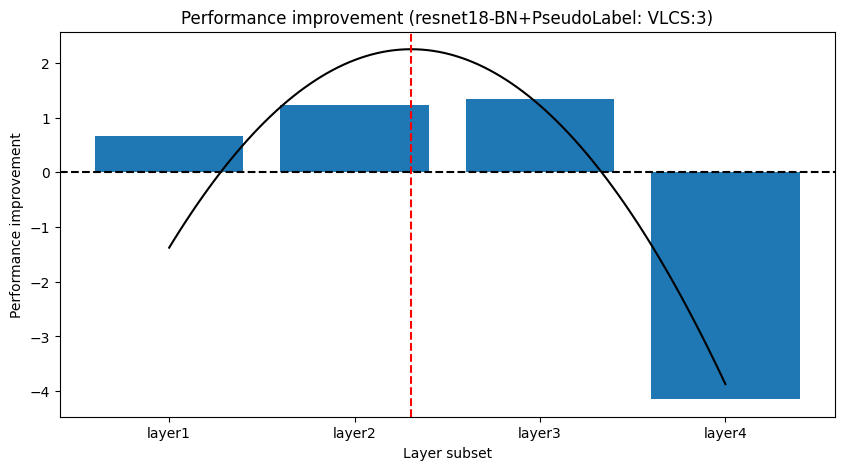

/tmp/ipykernel_1353822/3068444098.py:102: MatplotlibDeprecationWarning: The register_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.register(name)`` instead.
  matplotlib.cm.register_cmap(name, newcmap)


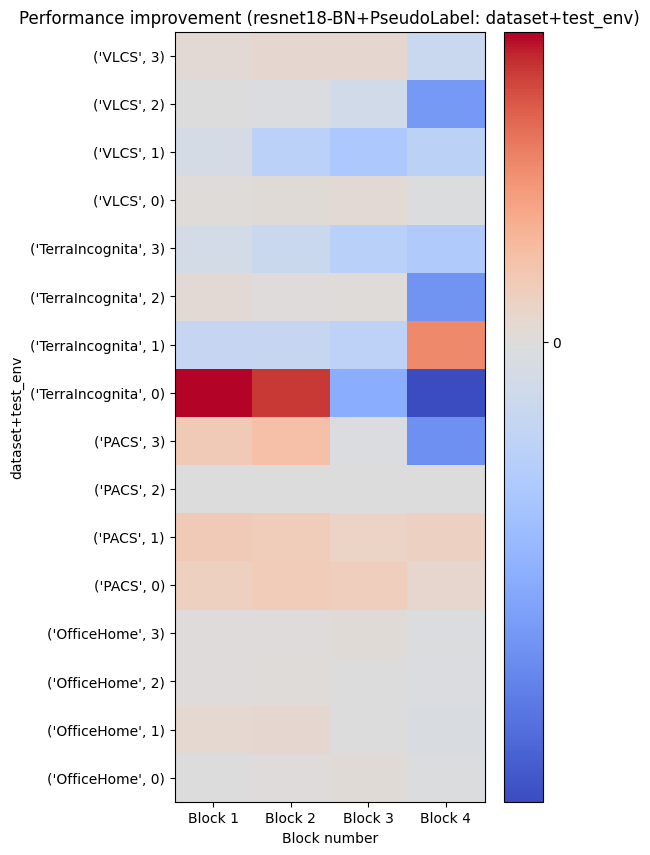

Filter by: resnet18-BN+SHOT


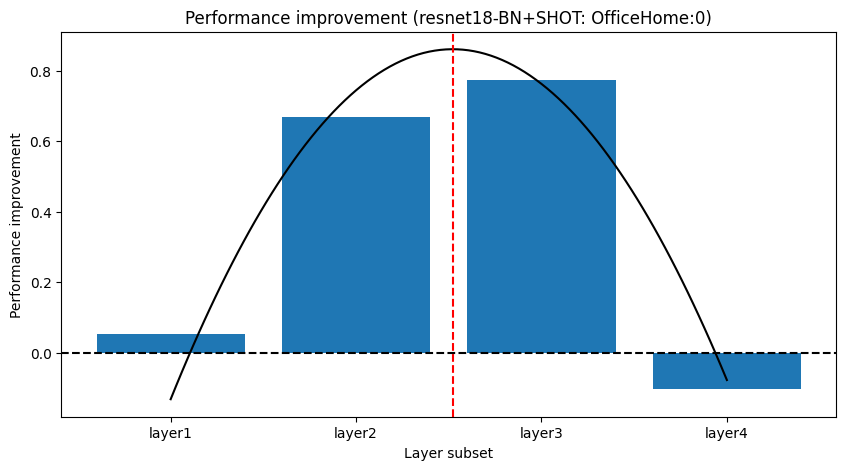

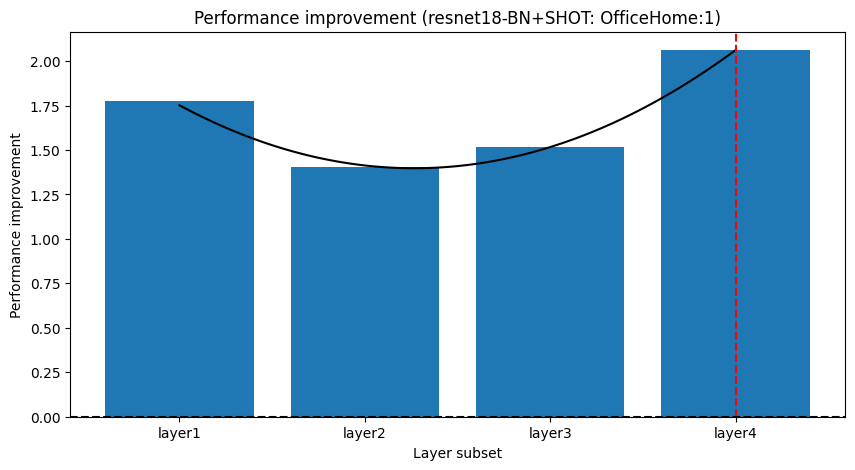

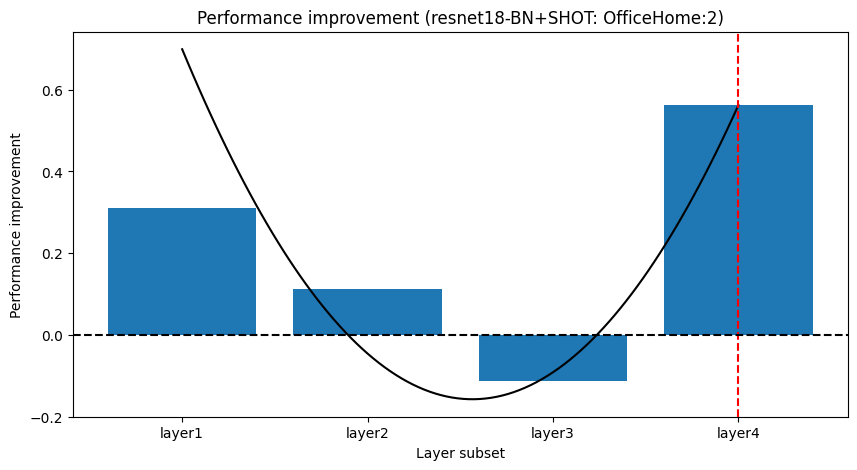

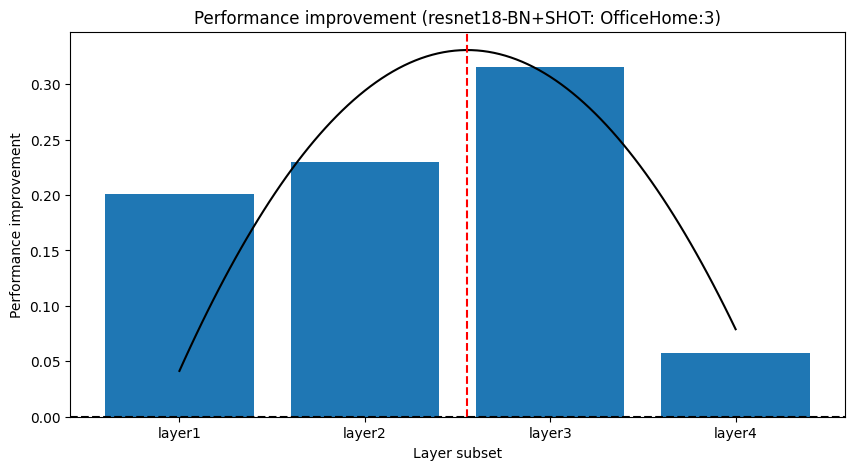

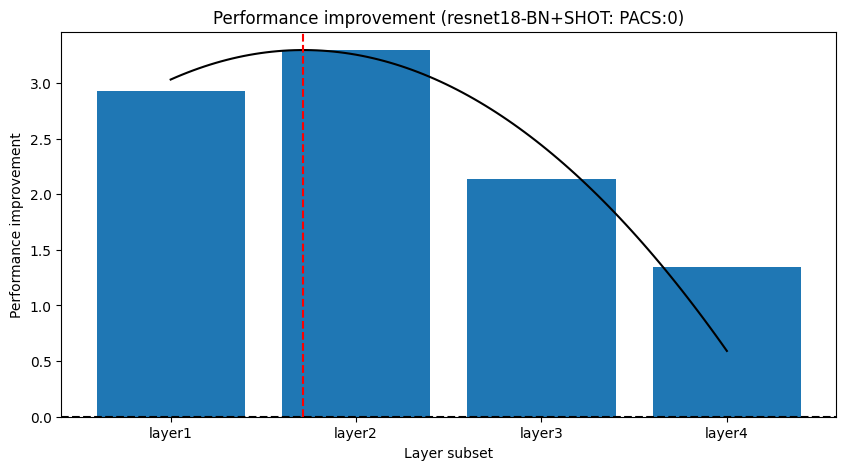

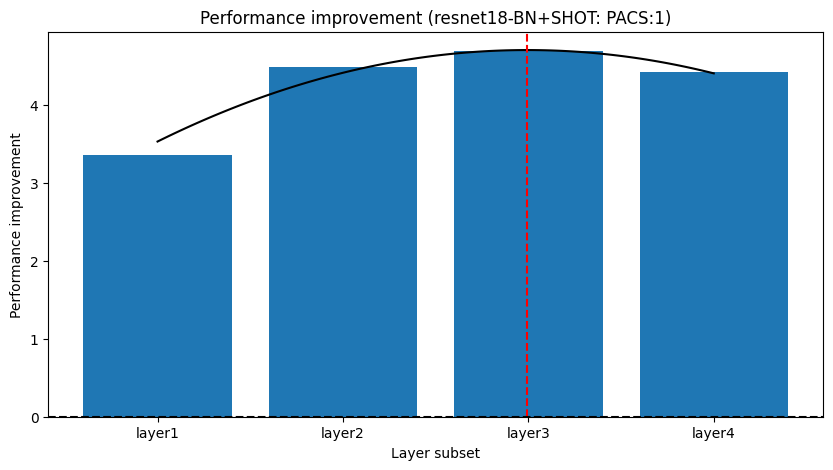

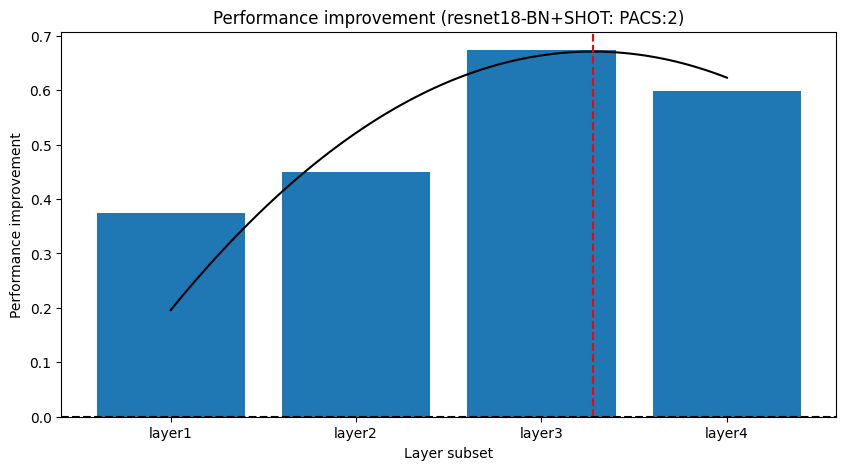

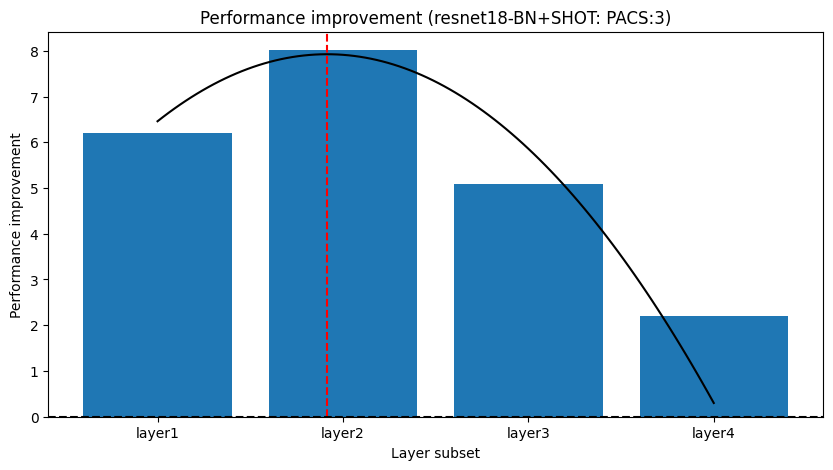

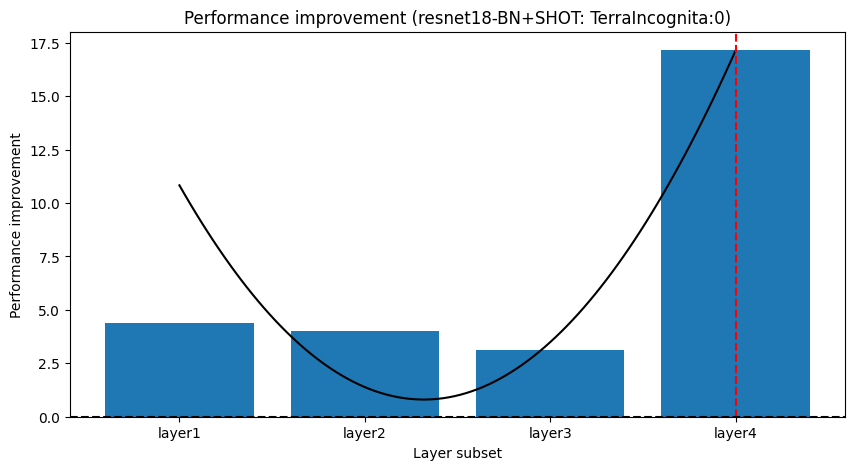

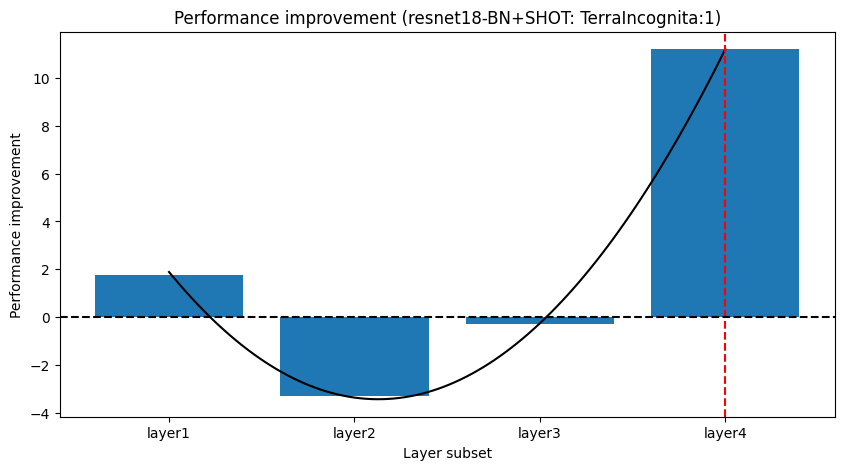

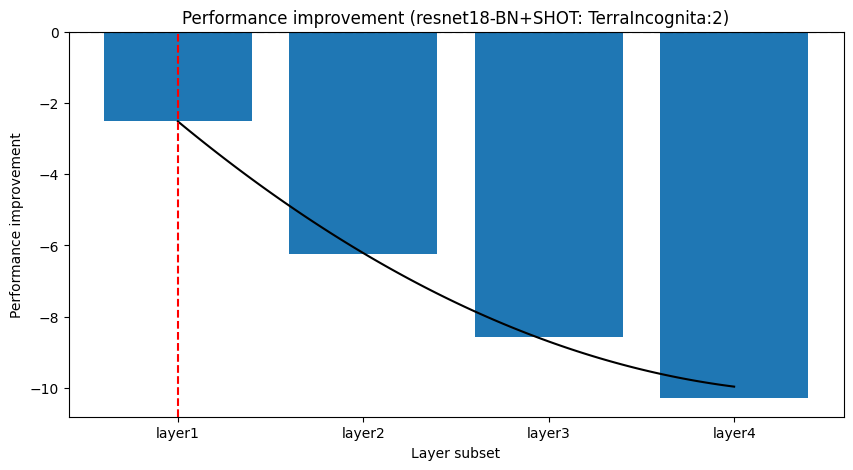

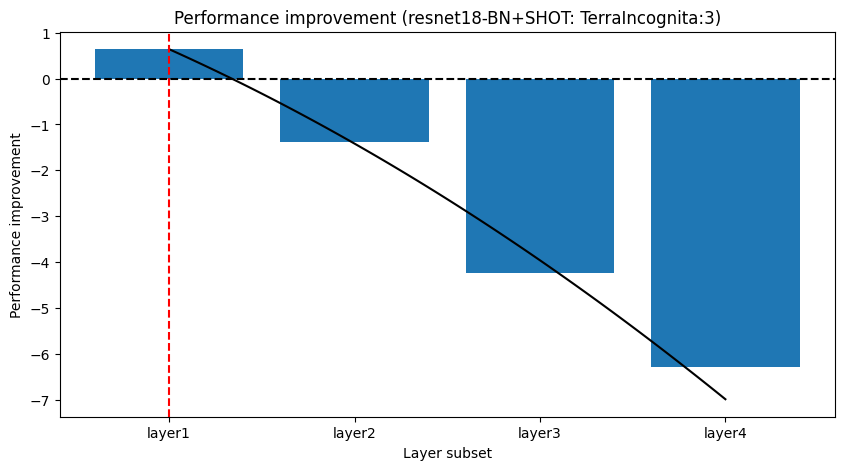

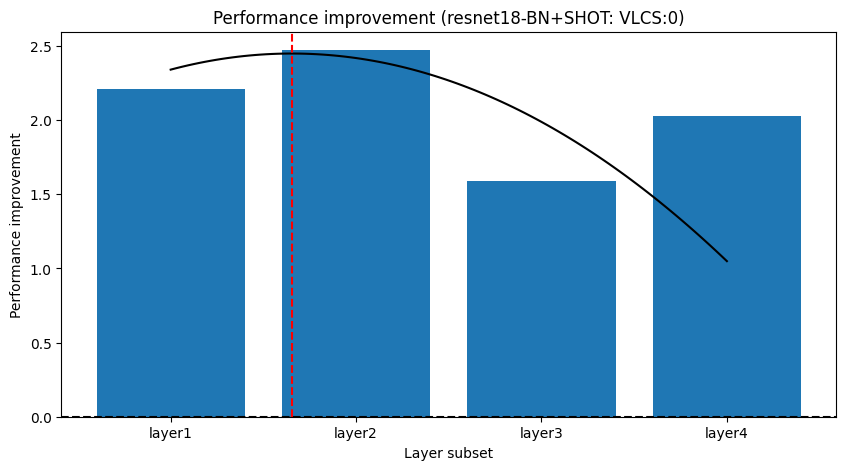

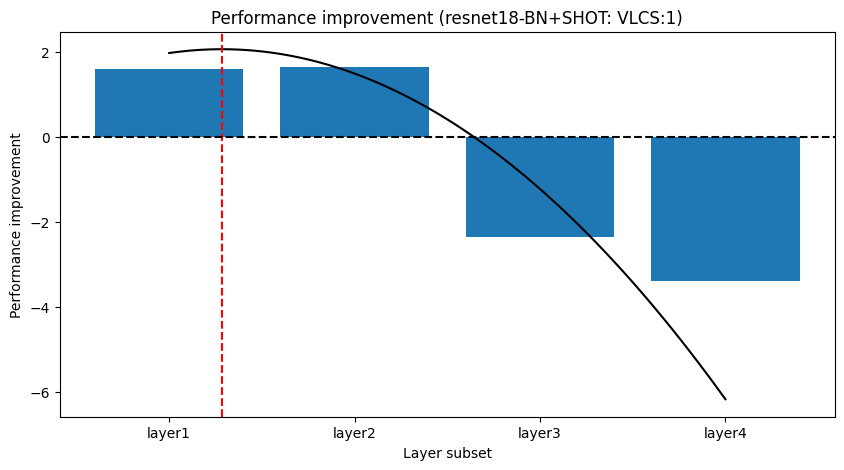

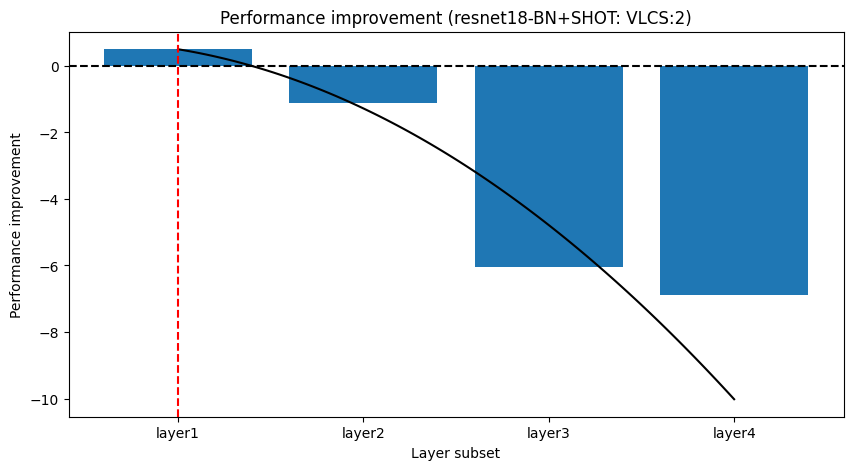

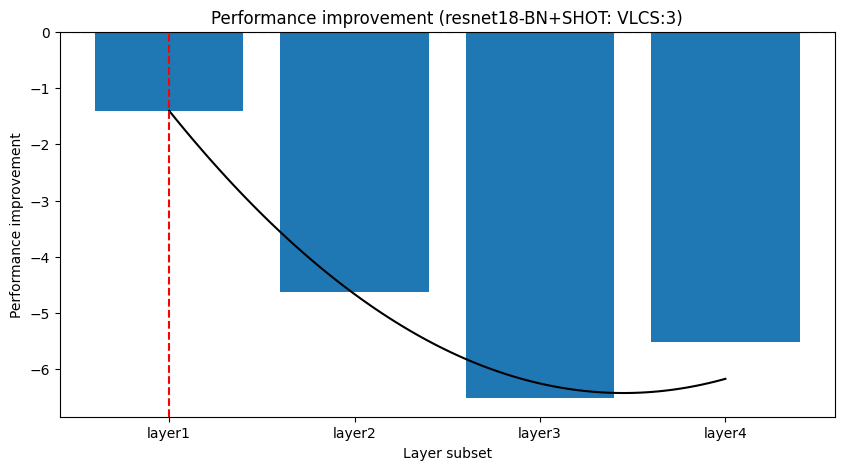

/tmp/ipykernel_1353822/3068444098.py:99: MatplotlibDeprecationWarning: The unregister_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.unregister(name)`` instead.
  matplotlib.cm.unregister_cmap(name)
/tmp/ipykernel_1353822/3068444098.py:102: MatplotlibDeprecationWarning: The register_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.register(name)`` instead.
  matplotlib.cm.register_cmap(name, newcmap)


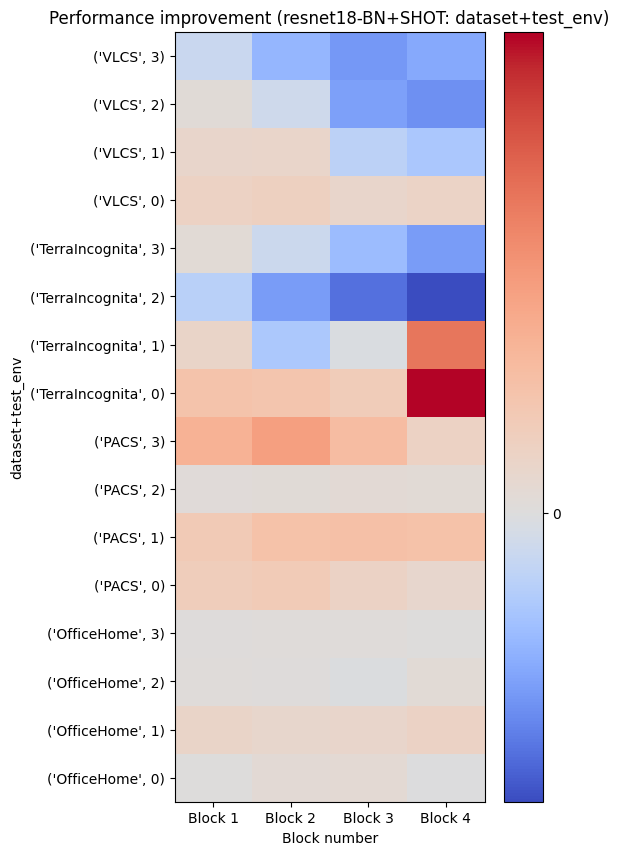

Filter by: resnet50-BN+PseudoLabel


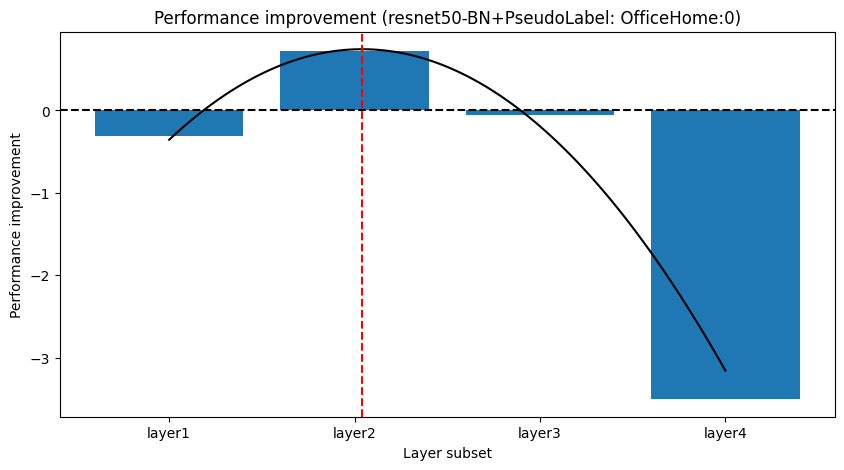

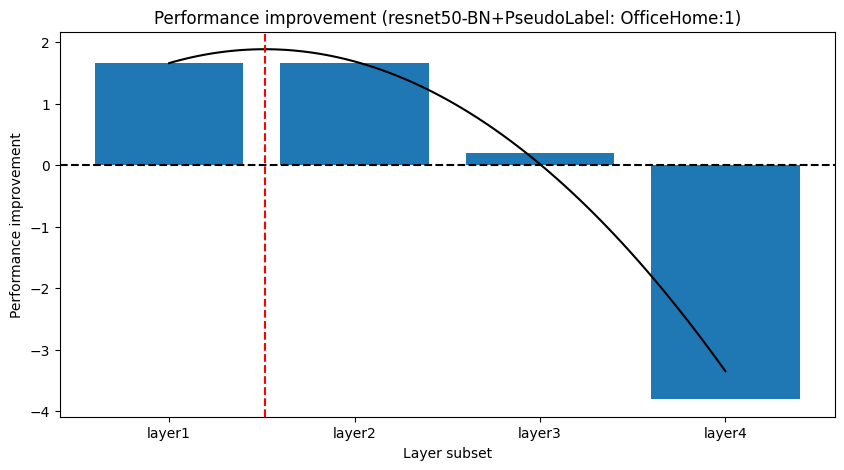

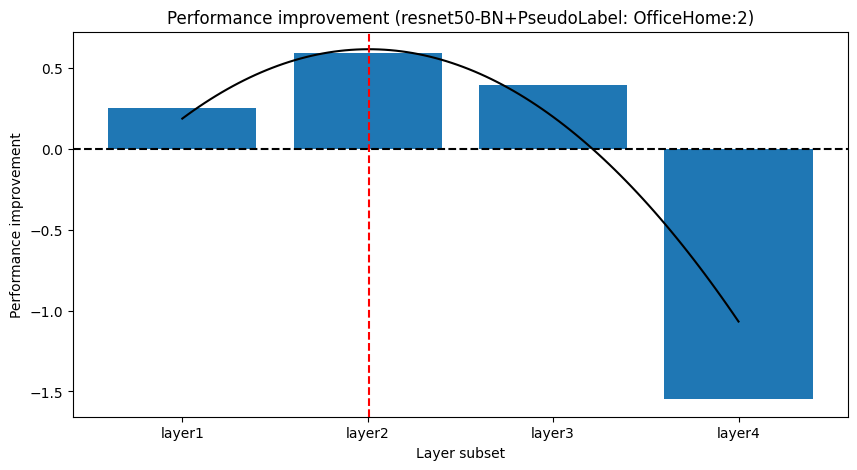

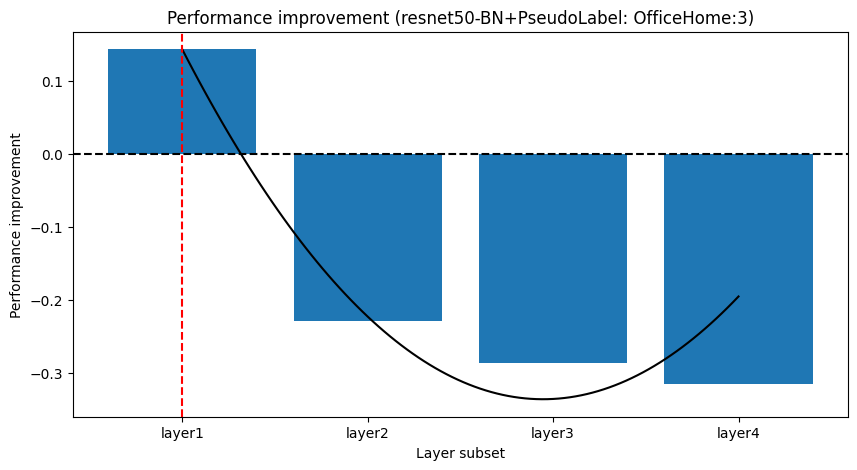

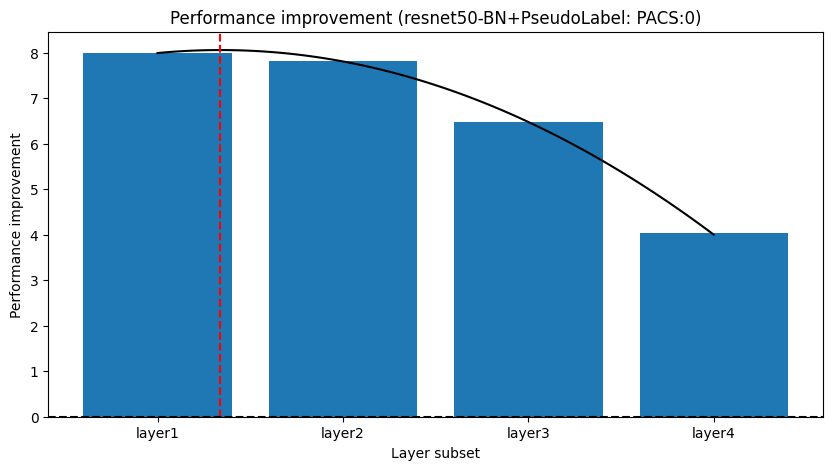

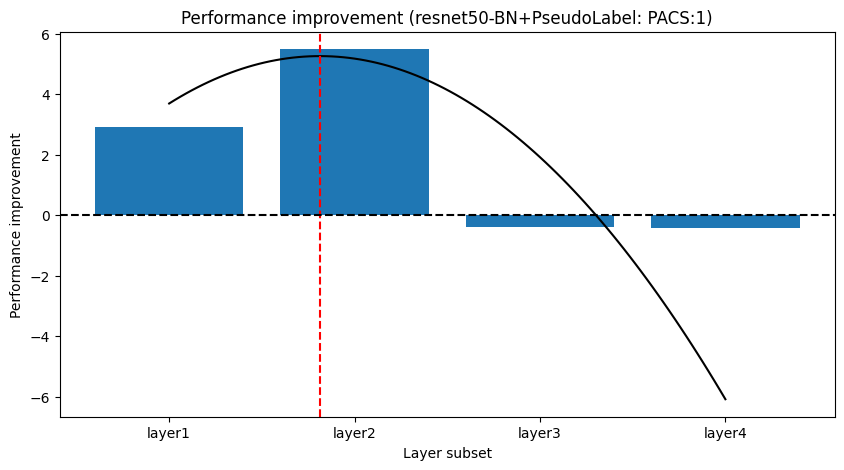

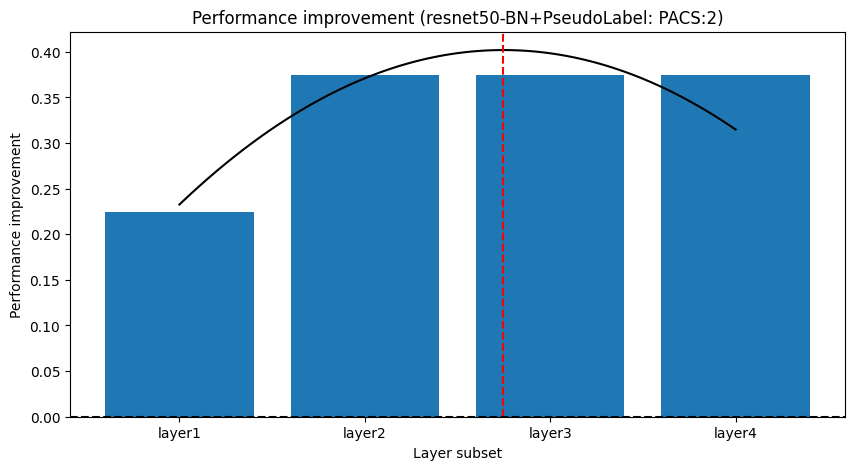

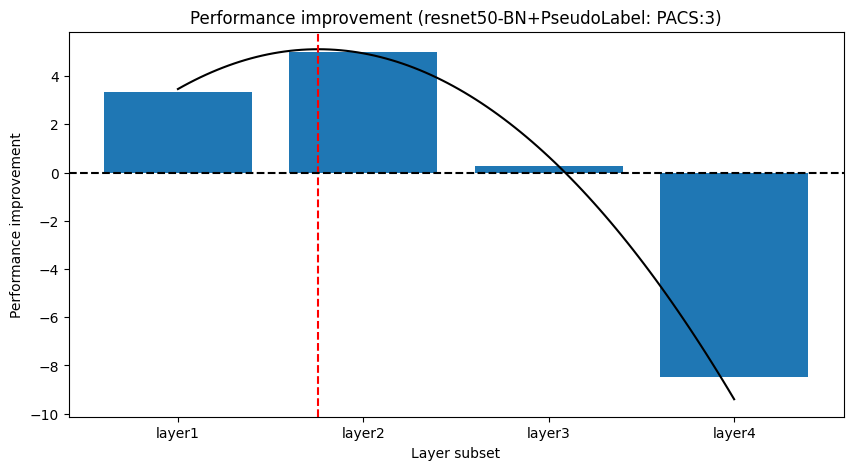

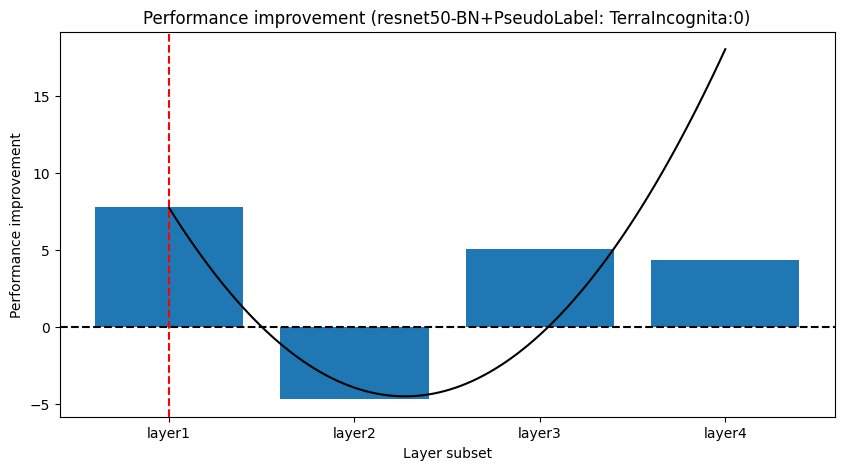

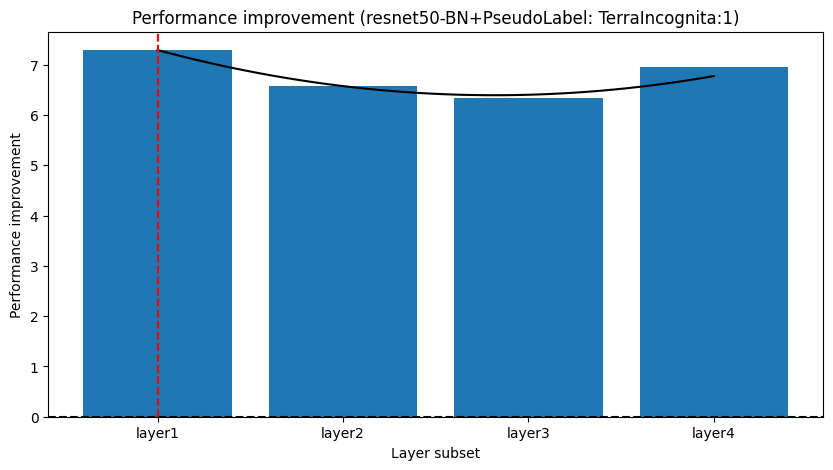

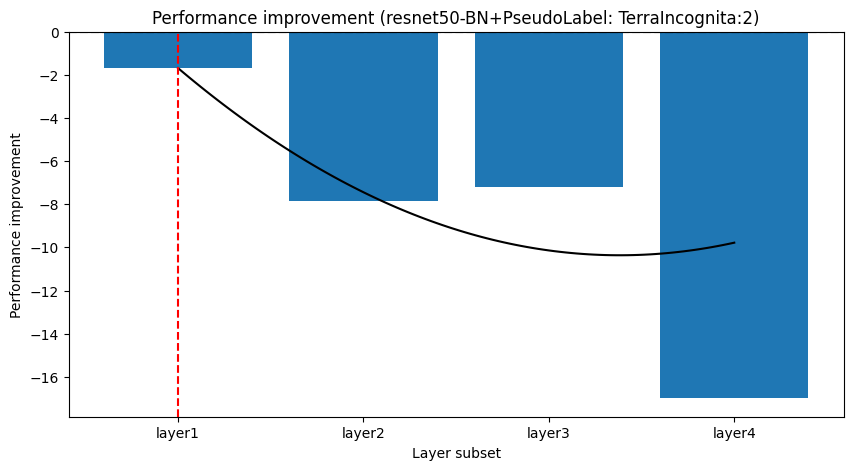

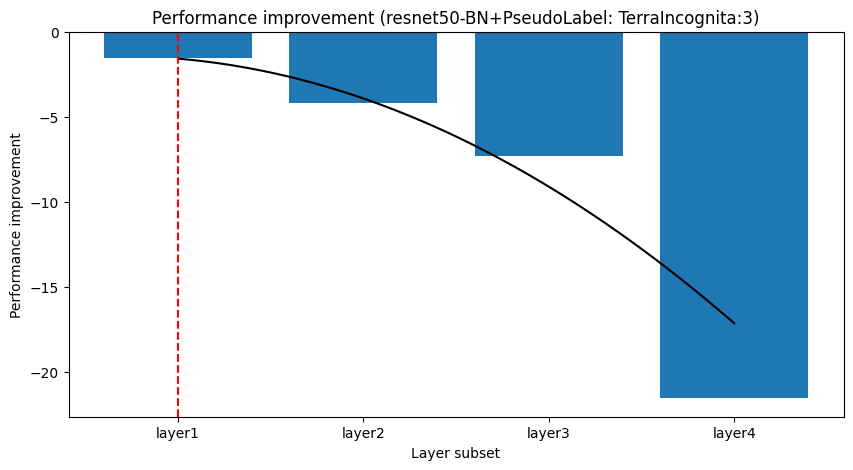

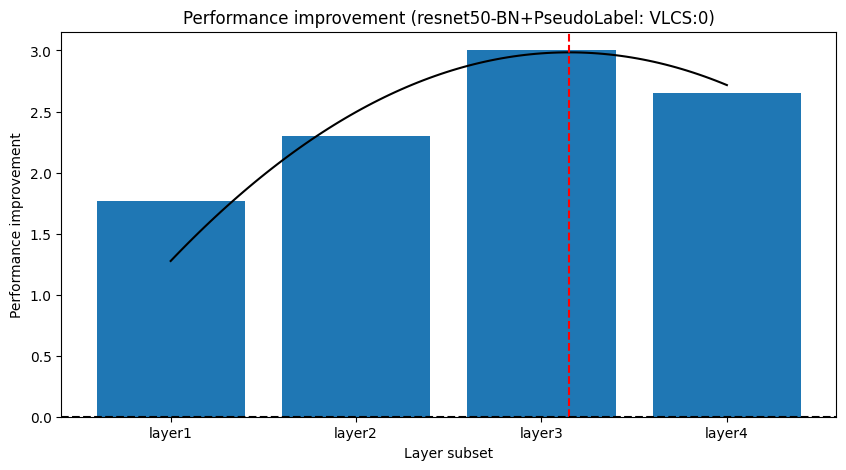

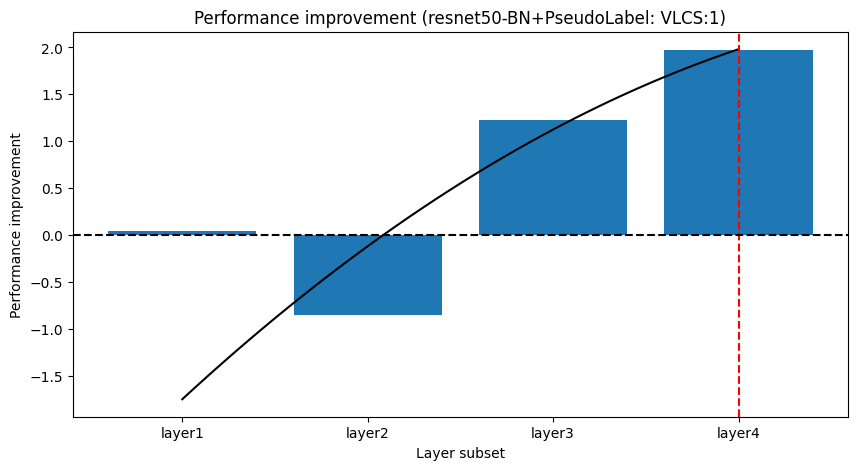

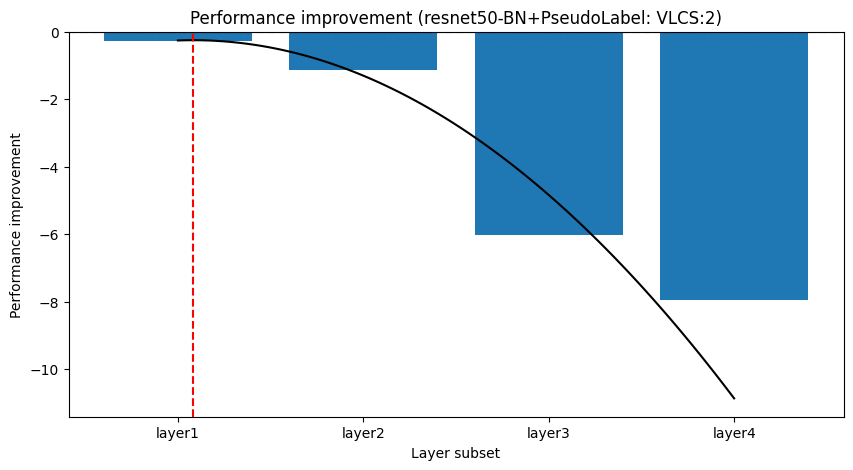

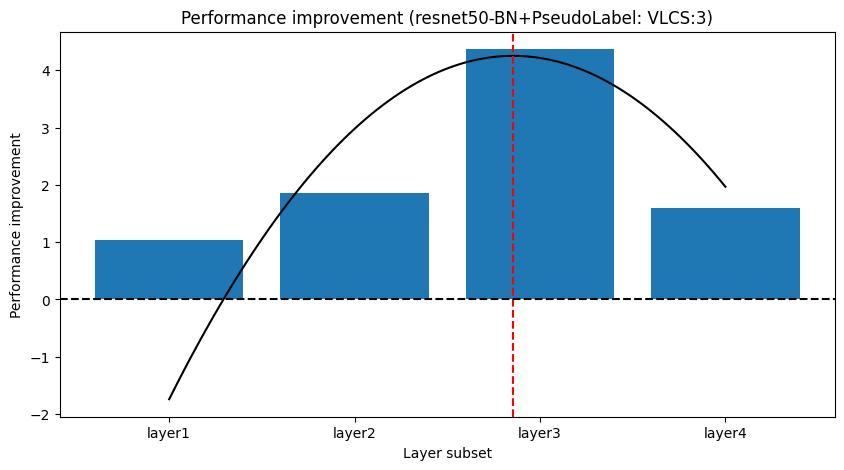

/tmp/ipykernel_1353822/3068444098.py:99: MatplotlibDeprecationWarning: The unregister_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.unregister(name)`` instead.
  matplotlib.cm.unregister_cmap(name)
/tmp/ipykernel_1353822/3068444098.py:102: MatplotlibDeprecationWarning: The register_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.register(name)`` instead.
  matplotlib.cm.register_cmap(name, newcmap)


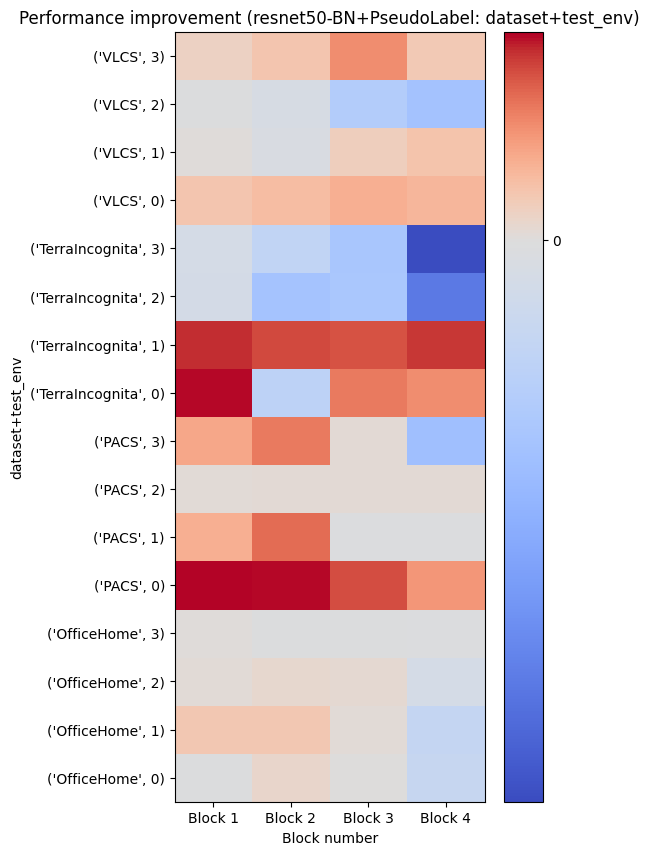

Filter by: resnet50-BN+SHOT


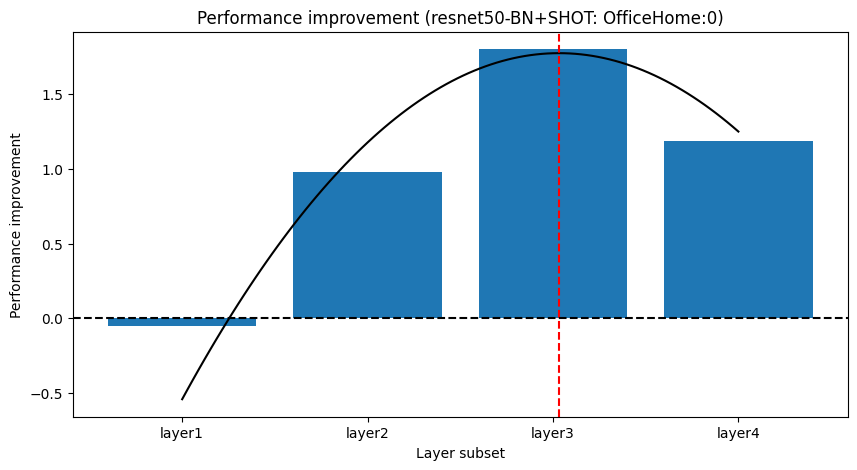

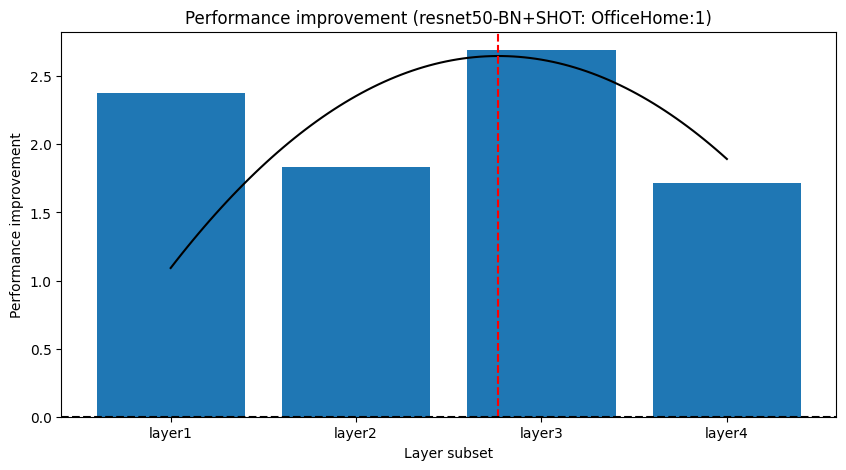

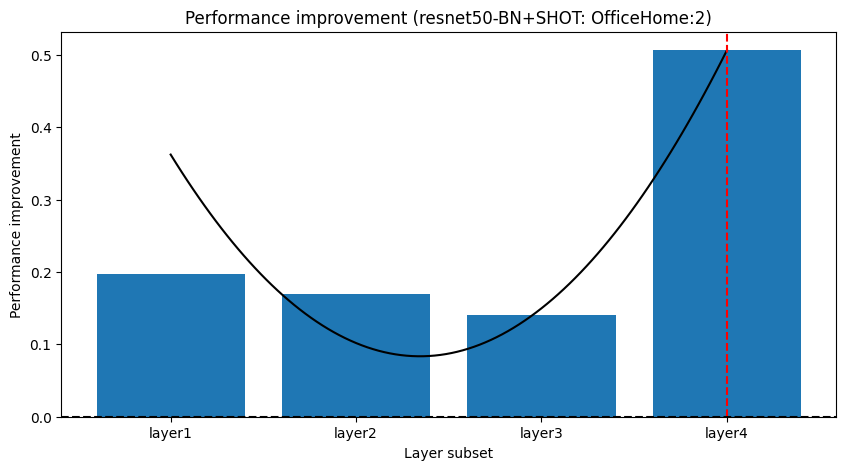

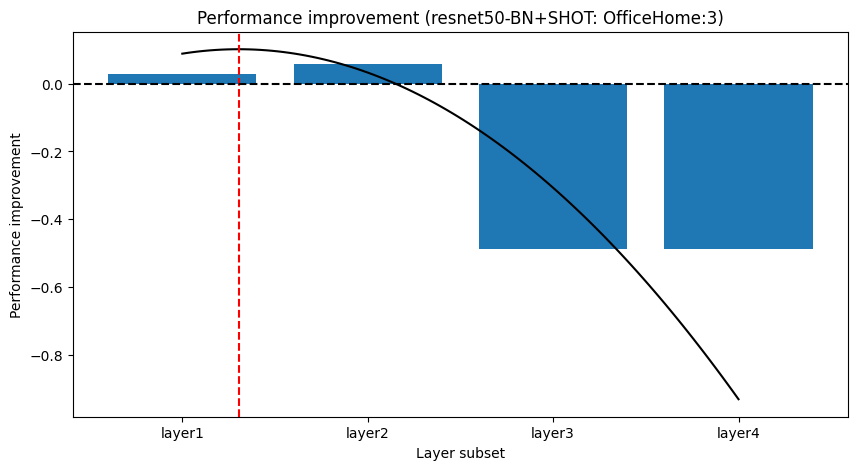

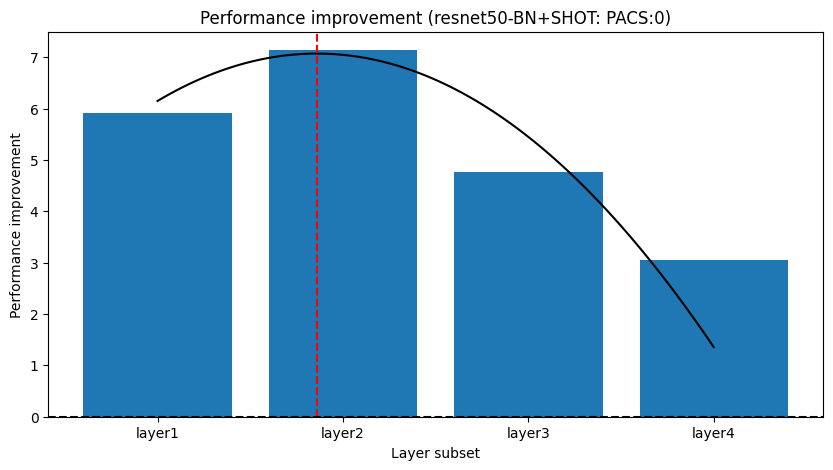

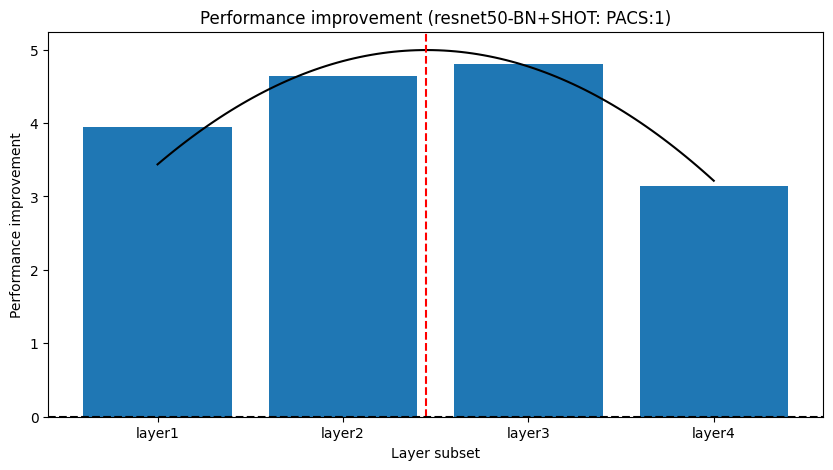

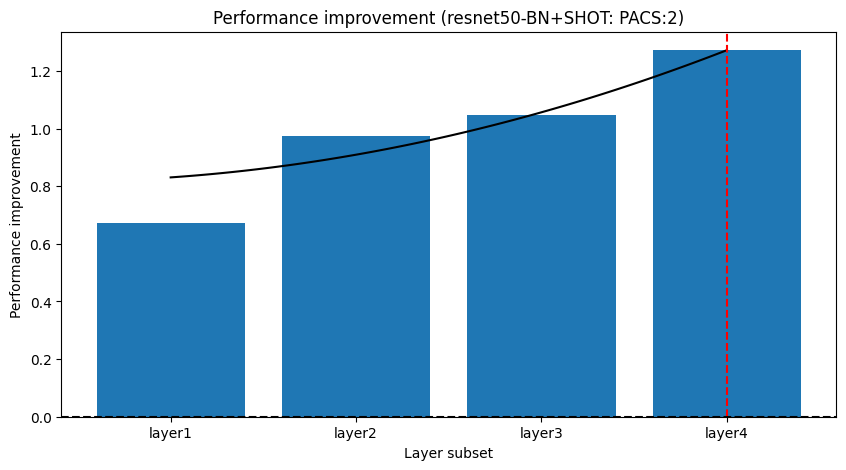

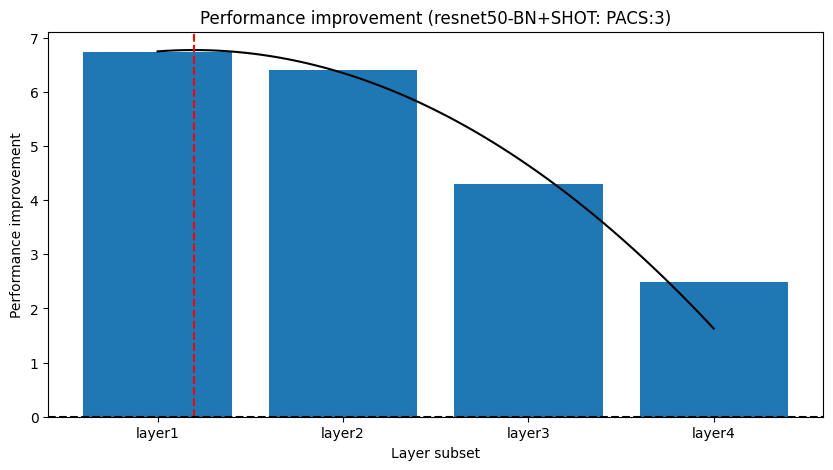

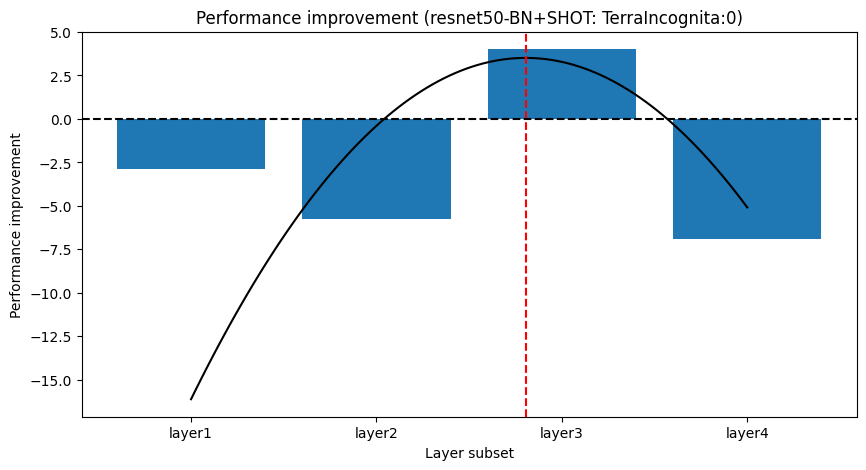

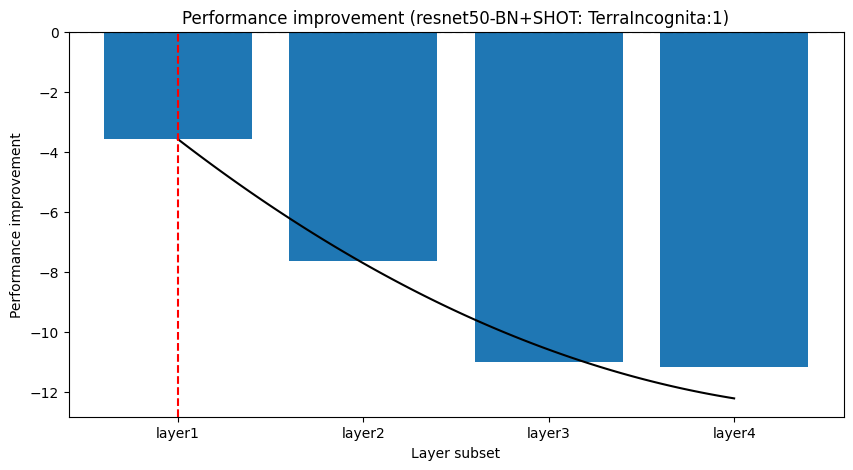

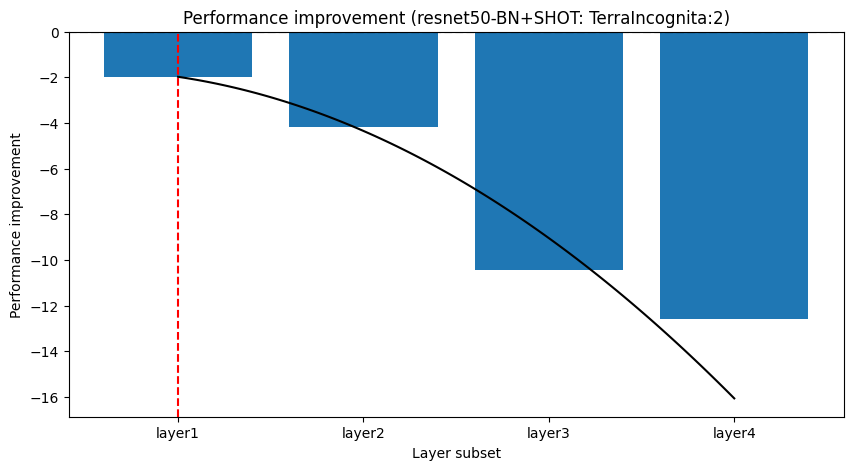

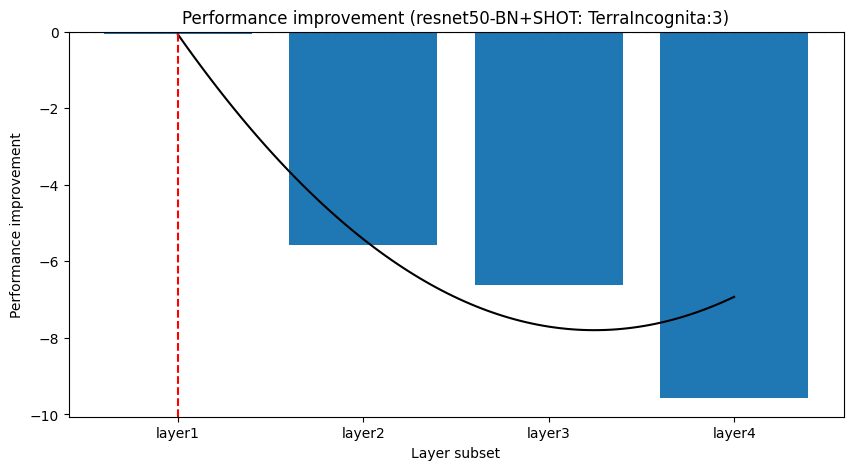

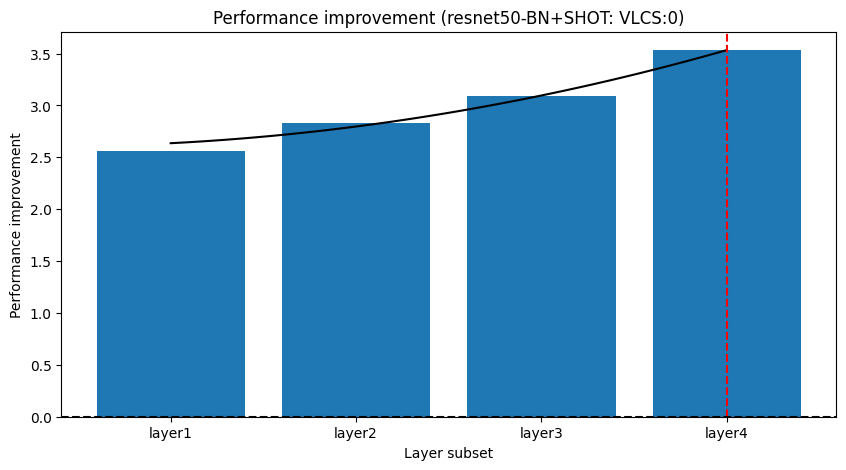

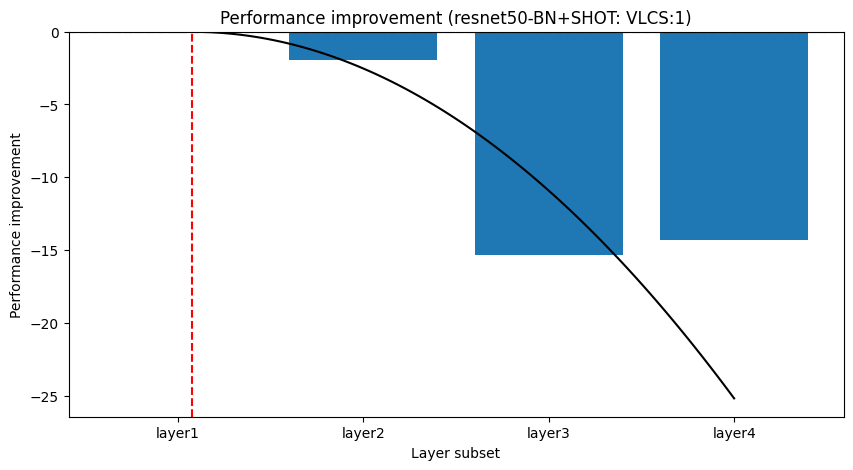

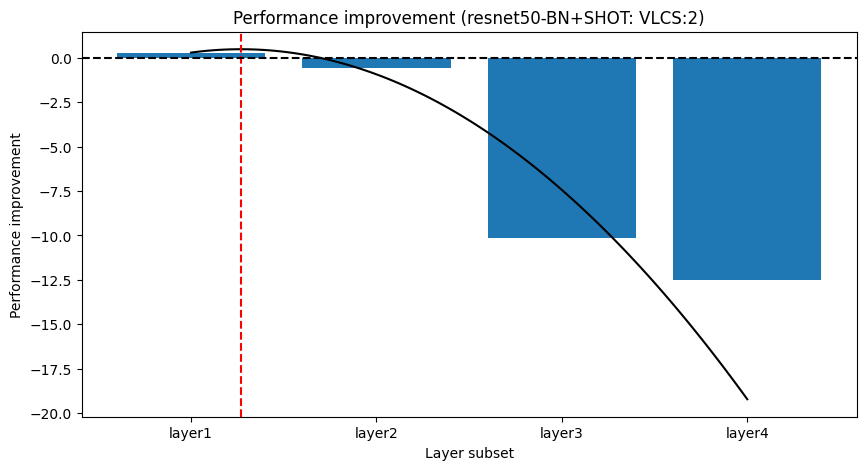

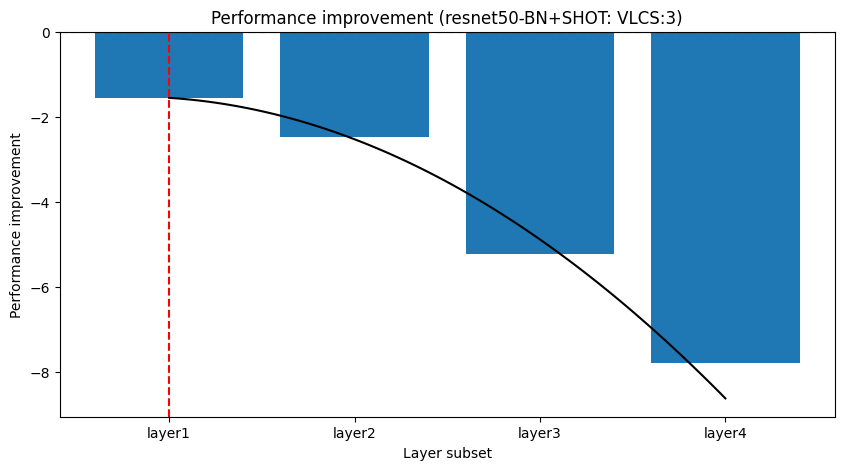

/tmp/ipykernel_1353822/3068444098.py:99: MatplotlibDeprecationWarning: The unregister_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.unregister(name)`` instead.
  matplotlib.cm.unregister_cmap(name)
/tmp/ipykernel_1353822/3068444098.py:102: MatplotlibDeprecationWarning: The register_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.register(name)`` instead.
  matplotlib.cm.register_cmap(name, newcmap)


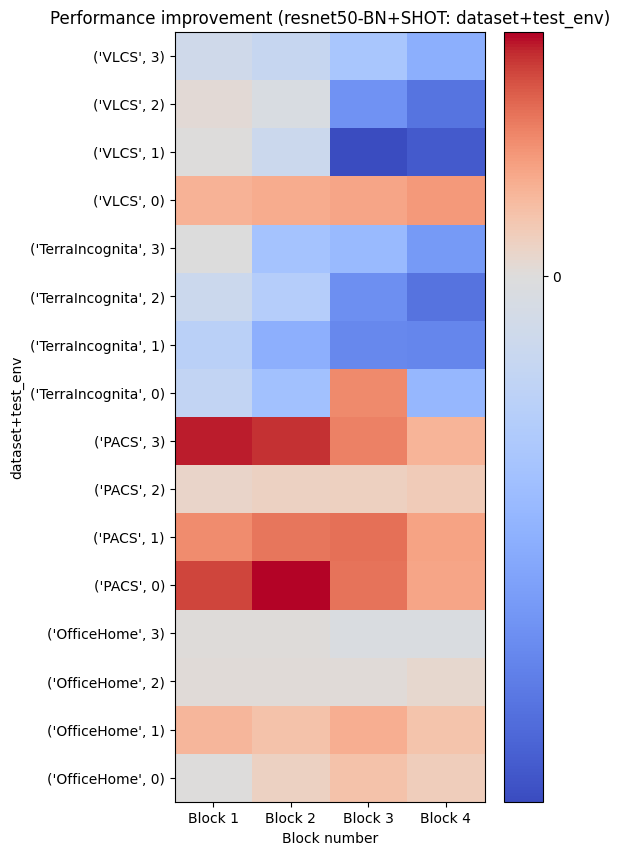

In [9]:
sort_flag = False
bar_plot = True
normalize = False

filter_by = ['backbone', 'tta']   # 'tta' or 'backbone' or 'dataset'
# filter_by = ['dg']           # or no filter -> which averages over all backbone, tta

layer_list = ['layer1', 'layer2', 'layer3', 'layer4']
# layer_list = ['layer0', 'layer1', 'layer2', 'layer3', 'layer4', 'classifier']

# group_by_list = [['dg'], ['backbone'], ['tta'], ['dataset'], ['dataset', 'test_env']]
group_by_list = [['dataset', 'test_env']]
# group_by_list = [['dataset']]

# tta_list = ['PseudoLabel', 'SHOT']
# backbone_list = ['resnet18', 'resnet50']
# dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'DomainNet']

orig_cmap = matplotlib.cm.coolwarm
# orig_cmap = matplotlib.cm.viridis
# orig_cmap = matplotlib.cm.rainbow

for filter_by_list, df_filter in df_best_hp.groupby(filter_by):
    filter_by_str = '+'.join(filter_by_list)
    print("Filter by:", filter_by_str)
    for group_by in group_by_list:
        perf_imprv_list = []
        perf_imprv_list_unnorm = []
        gname_list = []
        critical_point_list = []
        for idx, (glist, df_group) in enumerate(df_filter.groupby(group_by)):
            temp_list = []
            for layer_subset in layer_list + ['none']:
                temp_dict = {}
                temp_dict['layer_subset'] = layer_subset
                temp_dict['tta_acc'] = df_group[(df_group['find_algo'] == layer_subset)]['tta_acc'].mean()
                temp_list.append(temp_dict)

            df_temp = pd.DataFrame(temp_list)
            df_temp['tta_acc'] = df_temp['tta_acc'] - df_temp[df_temp['layer_subset'] == 'none']['tta_acc'].values[0]
            df_temp.drop(df_temp[df_temp['layer_subset'] == 'none'].index, inplace=True)

            perf_imprv_list_unnorm.append(df_temp['tta_acc'].values)

            # Perform min-max normalization
            if normalize:
                df_temp['tta_acc'] = (df_temp['tta_acc'] - df_temp['tta_acc'].min()) / (df_temp['tta_acc'].max() - df_temp['tta_acc'].min())

            this_perf_imprv = df_temp['tta_acc'].values
            perf_imprv_list.append(this_perf_imprv)
            gname_list.append(glist)

            xdata = np.arange(len(layer_list))
            ydata = this_perf_imprv
            x_curve, y_curve, critical_point = get_critical_point(xdata, ydata, degree=2)
            critical_point_list.append(critical_point)

            if bar_plot:
                plt.figure(figsize=(10, 5))
                plt.bar(xdata, ydata)
                plt.plot(x_curve, y_curve, c='k')
                plt.axvline(x=critical_point, color='r', linestyle='--')
                plt.axhline(y=0, color='k', linestyle='--', label='dg_acc')
                glist_str = ":".join([str(gl) for gl in glist])
                plt.title('Performance improvement' + " (" + filter_by_str +": "+ glist_str + ")")
                plt.xlabel("Layer subset")
                plt.ylabel("Performance improvement")
                plt.xticks(xdata, layer_list)
                plt.show()

                # if idx >= 3:
                #     break

        perf_imprvs = np.array(perf_imprv_list)
        perf_imprvs_unnorm = np.array(perf_imprv_list_unnorm)
        critical_points = np.array(critical_point_list)

        plt.figure(figsize=(5, 10))
        if sort_flag:
            sorted_idxs = np.argsort(critical_points)
            sorted_perf_imprvs = perf_imprvs[sorted_idxs]
            sorted_gnames = [gname_list[i] for i in sorted_idxs]

            if normalize:
                new_cmap = orig_cmap
                # new_cmap = matplotlib.cm.viridis
            else:
                new_cmap = shiftedColorMap(orig_cmap, sorted_perf_imprvs, name='shifted')
            plt.imshow(sorted_perf_imprvs, cmap=new_cmap, origin='lower', aspect='auto')
            
            plt.yticks(np.arange(len(sorted_gnames)), sorted_gnames)
        else:
            if normalize:
                new_cmap = orig_cmap
                # new_cmap = matplotlib.cm.viridis
            else:
                new_cmap = shiftedColorMap(orig_cmap, perf_imprvs, name='shifted')
            plt.imshow(perf_imprvs, cmap=new_cmap, origin='lower', aspect='auto')

            plt.yticks(np.arange(len(gname_list)), gname_list)

        if normalize:
            cbar = plt.colorbar()
            cbar.set_ticks([0, 1])
            cbar.set_ticklabels(['Barely Trainable', 'Highly Trainable'])
        else:
            cbar = plt.colorbar()
            cbar.set_ticks([0])
            cbar.set_ticklabels(['0'])

        plt.xticks(np.arange(len(layer_list)), ['Block 1', 'Block 2', 'Block 3', 'Block 4'])
        # plt.xticks(np.arange(len(layer_list)), ['Preconv', 'Block1', 'Block2', 'Block3', 'Block4', 'Clf'])
        plt.xlabel("Block number")
        group_by_str = '+'.join(group_by)
        plt.ylabel(group_by_str)
        plt.title("Performance improvement" + " (" + filter_by_str +": "+ group_by_str + ")")
        plt.show()

In [ ]:
critical_points+1       # approximately optimal layer index between block 1 and 4

array([2.45522263, 1.14423212, 1.72507363, 1.        , 1.80008343,
       1.92088007, 3.51661054, 1.72643539, 1.        , 4.        ,
       1.        , 1.        , 2.85368486, 1.        , 1.18083088,
       1.        ])

In [ ]:
perf_imprvs.argmax(axis=1) + 1     # optimal block number with max improvement

array([3, 1, 2, 1, 2, 2, 4, 2, 1, 4, 1, 1, 3, 1, 1, 1])

In [ ]:
np.round(critical_points+1)

array([2., 1., 2., 1., 2., 2., 4., 2., 1., 4., 1., 1., 3., 1., 1., 1.])

### Heuristics: dataset distribution and heatmap plots

In [ ]:
def get_metric_values_dict(metric_name, granularity, save_dir=None):
    if metric_name not in ['png', 'jpeg', 'fft']:
        raise NotImplementedError
    fname = metric_name + '_' + granularity + '_dict.pkl'
    if save_dir is None:
        save_dir = '/home-local2/sasah14.extra.nobkp/scratch/out/stta/metric_values/'
    metric_dict_fpath = os.path.join(save_dir, fname)

    # Check if pkl file exists in png_values_path
    if os.path.exists(metric_dict_fpath):
        print("Loading {}".format(metric_dict_fpath))
        with open(metric_dict_fpath, 'rb') as f:
            metric_dict = pickle.load(f)

        # Sort png_values by key
        metric_dict = dict(sorted(metric_dict.items(), key=lambda item: item[0]))

    # Else, create it
    else:
        print("Creating {}".format(metric_dict_fpath))
        # dataset_list = ['PACS']
        dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

        seed = 0
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        data_dir = '/home-local2/sasah14.extra.nobkp/scratch/data'
        holdout_fraction = 0
        batch_size = 32
        test_envs = [0]

        algorithm_name = 'ERM'
        model_dir = '/home-local2/sasah14.extra.nobkp/scratch/out/stta/single_run/vsDebug'
        device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

        metric_dict = {}
        for dataset_name in dataset_list:
            print("Processing dataset: {}".format(dataset_name))
            hparams = hparams_registry.default_hparams(algorithm_name, dataset_name)
            hparams.update({
                'data_augmentation': True,
                'backbone': 'resnet18-BN',
            })
            if dataset_name in vars(datasets):
                dataset = vars(datasets)[dataset_name](data_dir, test_envs, hparams)
            else:
                raise NotImplementedError

            full_splits = []
            for env_i, env in enumerate(dataset):
                _, full_split = misc.split_dataset(env, int(len(env)*holdout_fraction), misc.seed_hash(seed, env_i))
                full_split_weight = None
                full_splits.append((full_split, full_split_weight))

            # Use out splits as training data (to fair comparison with train.py)
            eval_loaders = [FastDataLoader(
                                dataset=env,
                                batch_size=batch_size,
                                num_workers=dataset.N_WORKERS)
                                    for _, (env, _) in enumerate(full_splits)]

            # eval_loader_names = ['env{}_in'.format(i) for i in range(len(full_splits))]
            eval_loader_names = [str(i) for i in range(len(full_splits))]

            eval_weights = [None for _, weights in full_splits]

            # algorithm_class = algorithms.get_algorithm_class(algorithm_name)
            # algorithm = algorithm_class(dataset.input_shape, dataset.num_classes,
            #     len(dataset) - len(test_envs), hparams)

            # algorithm.to(device)
            # if hasattr(algorithm, 'network'):
            #     algorithm.network = DataParallelPassthrough(algorithm.network)
            # else:
            #     for m in algorithm.children():
            #         m = DataParallelPassthrough(m)

            # # load trained model
            # ckpt = torch.load(os.path.join(model_dir, 'IID_best.pkl'))
            # algorithm_dict = ckpt['model_dict']
            # if algorithm_dict is not None:
            #     algorithm.load_state_dict(algorithm_dict)

            # loader_tuple = (eval_loader_names, eval_loaders, eval_weights)
            # src_info_dict = info_algorithms.store_src_info_dict(algorithm, find_algo, granularity,
            #                                                     find_algorithms.get_all_param_name_list,
            #                                                     loader_tuple, test_envs)

            if granularity == 'Block':
                n_parts = 4
            elif granularity == 'Subblock':
                n_parts = 8
            elif granularity == 'Layer':
                n_parts = 16
            if metric_name == 'fft':
                n_feats = n_parts
            elif metric_name in ['png', 'jpeg']:
                n_feats = 1

            
            for name, loader in tqdm(zip(eval_loader_names, eval_loaders), total=len(eval_loaders)):
                x_info_list = [[] for _ in range(n_feats)]
                for x, y in loader:
                    if metric_name == 'png':
                        x_info = info_algorithms.png_info(x)
                    elif metric_name == 'jpeg':
                        x_info = info_algorithms.jpeg_info(x)
                    elif metric_name == 'fft':
                        x_info = info_algorithms.fft_info(x, n_parts)
                    else:
                        raise NotImplementedError
                    for j in range(n_feats):
                        x_info_list[j].append(x_info[j])
                all_x_info_list = [torch.cat(x_info_list[feat_idx], dim=0) for feat_idx in range(n_feats)]
                metric_dict[dataset_name+":"+name] = all_x_info_list

                # metric_dict[dataset_name+":"+str(test_envs[0])] = src_info_dict

        # Sort png_values by key
        metric_dict = dict(sorted(metric_dict.items(), key=lambda item: item[0]))

        # Save png_values to png_values_path
        with open(metric_dict_fpath, 'wb') as f:
            pickle.dump(metric_dict, f)
    
    return metric_dict

def get_feat_idx_dict(metric_dict, feat_idx=0):
    if feat_idx not in range(len(metric_dict[list(metric_dict.keys())[0]])):
        raise ValueError
    metric_dict = {k:v[feat_idx].mean(dim=1).numpy() for k, v in metric_dict.items()}
    return metric_dict

def calculate_feature_shift(batch1, batch2, extractor='dct', metric='euclidean'):
    # Possible extractors: 'fft', 'dct'
    # Possible metrics: 'euclidean', 'cosine', 'correlation', 'hamming', 'jaccard', 'chebyshev', 'canberra', 'cityblock', 'braycurtis'
    # Extract the features from the two batches
    if extractor == 'fft':
        high_level_features1, low_level_features1 = fft_feat(batch1)
        high_level_features2, low_level_features2 = fft_feat(batch2)
    elif extractor == 'dct':
        high_level_features1, low_level_features1 = dct_feat(batch1)
        high_level_features2, low_level_features2 = dct_feat(batch2)

    # Flatten the features
    high_level_features1 = high_level_features1.reshape(high_level_features1.shape[0], -1)
    low_level_features1 = low_level_features1.reshape(low_level_features1.shape[0], -1)
    high_level_features2 = high_level_features2.reshape(high_level_features2.shape[0], -1)
    low_level_features2 = low_level_features2.reshape(low_level_features2.shape[0], -1)

    # Calculate the Euclidean distance between the features
    high_level_shift = cdist(high_level_features1, high_level_features2, metric=metric)
    low_level_shift = cdist(low_level_features1, low_level_features2, metric=metric)

    return low_level_shift, high_level_shift

def fft_feat(x):
    # Perform FFT on the image batch
    f = torch.fft.fftn(x)
    fshift = torch.fft.fftshift(f)

    # Create a mask for low frequency components
    rows, cols = x.shape[2], x.shape[3]
    crow, ccol = rows//2 , cols//2
    mask_low = torch.zeros((1, 1, rows, cols)).to(x.device)
    mask_low[:, :, crow-30:crow+30, ccol-30:ccol+30] = 1

    # Apply mask and inverse FFT for low frequency components
    fshift_low = fshift*mask_low
    f_ishift_low = torch.fft.ifftshift(fshift_low)
    img_back_low = torch.fft.ifftn(f_ishift_low)
    img_back_low = torch.abs(img_back_low)

    # Create a mask for high frequency components
    mask_high = torch.ones((1, 1, rows, cols)).to(x.device)
    mask_high[:, :, crow-30:crow+30, ccol-30:ccol+30] = 0

    # Apply mask and inverse FFT for high frequency components
    fshift_high = fshift*mask_high
    f_ishift_high = torch.fft.ifftshift(fshift_high)
    img_back_high = torch.fft.ifftn(f_ishift_high)
    img_back_high = torch.abs(img_back_high)

    # Return the low and high frequency components
    return img_back_low, img_back_high

def dct_feat(x):
    # Convert the image batch to numpy array
    img_np = x.numpy()

    # Perform DCT on the image
    dct_img = np.array([dct(dct(img.T, norm='ortho').T, norm='ortho') for img in img_np])

    # The low frequency component is in the top-left corner of the DCT
    low_freq = dct_img[:, :dct_img.shape[1]//2, :dct_img.shape[2]//2]

    # The high frequency components are in the other parts of the DCT
    high_freq = dct_img[:, dct_img.shape[1]//2:, dct_img.shape[2]//2:]

    # Return the low and high frequency components
    return torch.from_numpy(low_freq), torch.from_numpy(high_freq)

def get_high_feat_png_jpg(x):
    mean=torch.Tensor([0.485, 0.456, 0.406]).view(1,3,1,1).to(x.device)
    std=torch.Tensor([0.229, 0.224, 0.225]).view(1,3,1,1).to(x.device)

    x = (x * std + mean) * 255.
    x = x.to(torch.uint8).detach().cpu()

    complexity = []
    for x_i in x:
        high_feat_x_i = decode_jpeg(encode_jpeg(x_i))
        high_feat_info = len(encode_png(high_feat_x_i))
        complexity.append(high_feat_info)
    complexity = np.array(complexity)

    return complexity

def get_low_feat_png_jpg(x):
    mean=torch.Tensor([0.485, 0.456, 0.406]).view(1,3,1,1).to(x.device)
    std=torch.Tensor([0.229, 0.224, 0.225]).view(1,3,1,1).to(x.device)

    x = (x * std + mean) * 255.
    x = x.to(torch.uint8).detach().cpu()

    complexity = []
    for x_i in x:
        high_feat_x_i = decode_jpeg(encode_jpeg(x_i))
        low_feat_x_i = x_i - high_feat_x_i
        low_feat_info = len(encode_png(low_feat_x_i))
        complexity.append(low_feat_info)
    complexity = np.array(complexity)

    return complexity

def get_density_values(metric_dict, bin_size=20, common_x_values=True, normalize=True, plot=False):
    # Generate x values for the plot
    if common_x_values:
        # get min and max png values over all envs
        min_value = np.inf
        max_value = -np.inf
        for value in metric_dict.values():
            min_value = min(min_value, value.min())
            max_value = max(max_value, value.max())

        x_values = np.linspace(min_value, max_value, bin_size)

    ### density distribution curves of png values for each env in a single plot
    # Create a new figure and axis
    if plot:
        fig, ax = plt.subplots()

    density_list = []
    density_dict = {}
    for key, values in metric_dict.items():
        # Compute the density distribution using Gaussian KDE
        density_fn = gaussian_kde(values)

        # Generate x values for the plot
        if not common_x_values:
            x_values = np.linspace(values.min(), values.max(), bin_size)

        # Compute the density values for the x values
        y_values = density_fn(x_values)

        # Perform min-max normalization
        if normalize:
            y_values = (y_values - y_values.min()) / (y_values.max() - y_values.min())

        # Plot the density distribution curve for the current key
        if plot:
            ax.plot(x_values, y_values, label=key)

        # Store the density values in a list and dictionary
        density_list.append(y_values.reshape(1, -1))
        density_dict[key] = y_values

    # Concatenate the density values into a single array
    density_arr = np.concatenate(density_list, axis=0)

    if plot:
        # Set labels and title
        ax.set_xlabel('Metric value of image')
        ax.set_ylabel('Density')
        ax.set_title('Metric value Density Distribution Plot')

        # Add legend to the plot
        ax.legend()

        # Show the plot
        plt.show()

    if plot and False:
        ### density distribution range box plots of png values for each env in a single plot
        # Extract the values from the dictionary and store them in a list
        data_values = [metric_dict[key] for key in metric_dict]

        # Create a new figure and axis
        fig, ax = plt.subplots()

        # Create the box plot
        ax.boxplot(data_values, labels=metric_dict.keys(), whis=[0, 100])

        # Set labels and title
        ax.set_xlabel('Domain')
        ax.set_ylabel('Metric value of image')
        ax.set_title('Metric value Range Box Plots')
        ax.set_xticklabels(metric_dict.keys(), rotation=90)

        # Show the plot
        plt.show()

    return density_arr, density_dict

def plot_heatmap(metric_dict, sort_flag=True, bin_size=20, common_x_values=True, normalize=True):
    density_values, _ = get_density_values(metric_dict, bin_size=bin_size, common_x_values=common_x_values, normalize=normalize, plot=False)
    data_keys = list(metric_dict.keys())

    if sort_flag:
        argmax_idxs =  np.argmax(density_values, axis=1)
        sorted_idxs = np.argsort(argmax_idxs)

        sorted_density_values = density_values[sorted_idxs]
        sorted_data_keys = [data_keys[i] for i in sorted_idxs]

    plt.figure(figsize=(5, 10))
    if sort_flag:
        plt.imshow(sorted_density_values, cmap='viridis', origin='lower', aspect='auto')
        plt.yticks(np.arange(len(sorted_data_keys)), sorted_data_keys)
    else:
        plt.imshow(density_values, cmap='viridis', origin='lower', aspect='auto')
        plt.yticks(np.arange(len(data_keys)), data_keys)

    cbar = plt.colorbar()

    plt.xlabel("Metric value of Image")
    plt.ylabel('Domain')

    plt.title("Metric value Density Distribution Plot")

def evaluate_dists(heuristic_values, critical_points, granularity):
    if granularity == 'Block':
        heuristic_density_values, _ = get_density_values(heuristic_values, bin_size=4, common_x_values=False, normalize=False, plot=False)
        critical_factor = 1
    elif granularity == 'Subblock':
        heuristic_density_values, _ = get_density_values(heuristic_values, bin_size=8, common_x_values=False, normalize=False, plot=False)
        critical_factor = 2
    elif granularity == 'Layer':
        heuristic_density_values, _ = get_density_values(heuristic_values, bin_size=16, common_x_values=False, normalize=False, plot=False)
        critical_factor = 4
    
    identified_boxes = np.argmax(heuristic_density_values, axis=1)

    err_dists = np.abs(identified_boxes - critical_points*critical_factor)
    return err_dists

def evaluate_imprvs(heuristic_values, perf_imprvs_unnorm, granularity):
    if granularity == 'Block':
        heuristic_density_values, _ = get_density_values(heuristic_values, bin_size=4, common_x_values=False, normalize=False, plot=False)
    elif granularity == 'Subblock':
        heuristic_density_values, _ = get_density_values(heuristic_values, bin_size=8, common_x_values=False, normalize=False, plot=False)
    elif granularity == 'Layer':
        heuristic_density_values, _ = get_density_values(heuristic_values, bin_size=16, common_x_values=False, normalize=False, plot=False)
    
    identified_boxes = np.argmax(heuristic_density_values, axis=1)

    imprvs = []
    for perf_imprv, identified_box in zip(perf_imprvs_unnorm, identified_boxes):
        ydata = perf_imprv
        xdata = np.arange(len(ydata))
        coefficients = get_polyfit_coeffs(xdata, ydata, degree=2)

        # evaluate identified_box at the polynomial
        identified_imprv = np.polyval(coefficients, identified_box)
        imprvs.append(identified_imprv)

    return np.array(imprvs)

Png distribution over dataset plots

In [ ]:
png_values_list = get_metric_values_dict('fft', 'Block')
png_values_list

Loading /home-local2/sasah14.extra.nobkp/scratch/out/stta/metric_values/fft_Block_dict.pkl


{'OfficeHome:0': [tensor([[25343.5625,  8936.3203,  2289.2830,  ...,  2800.5015,   977.7203,
            8498.7676],
          [31919.7422,  9000.1221,  6649.7412,  ...,  1686.4791,  6443.2114,
            3988.5356],
          [47732.1133, 10813.6699,  5063.1323,  ...,  4063.0630,  1687.4677,
           10478.8457],
          ...,
          [85124.5703, 10862.9160,  3849.5396,  ...,  4267.6738,  5096.0742,
            6084.3462],
          [47066.2109,  7351.0723,  4754.5122,  ...,   984.6719,  1328.0149,
            6266.8384],
          [60863.7891, 18588.9180,  8606.6504,  ...,  4935.9077,  7235.4263,
            4380.4971]]),
  tensor([[125.4797,  89.8284,  74.1070,  ...,  27.5909,  25.9602,  84.2416],
          [112.4665, 134.8437, 159.6015,  ...,  39.0101,  50.6983,  90.7631],
          [214.8398,  73.7405,  61.3986,  ...,  73.3855, 183.1658, 123.0152],
          ...,
          [122.9028,  56.7385,  50.9283,  ...,  35.9799,  41.1560,  54.8752],
          [114.8517, 105.0477,  98

PACS


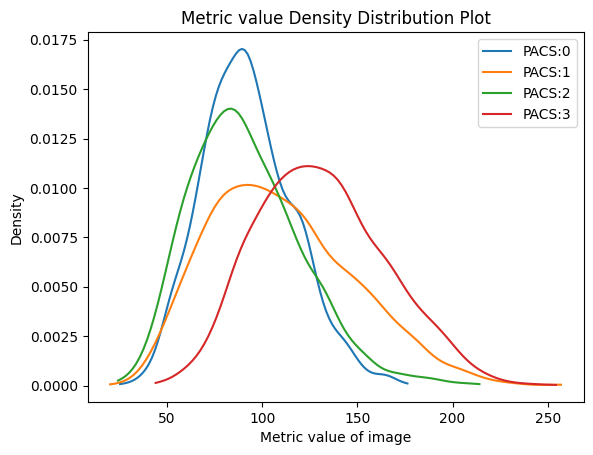

PACS


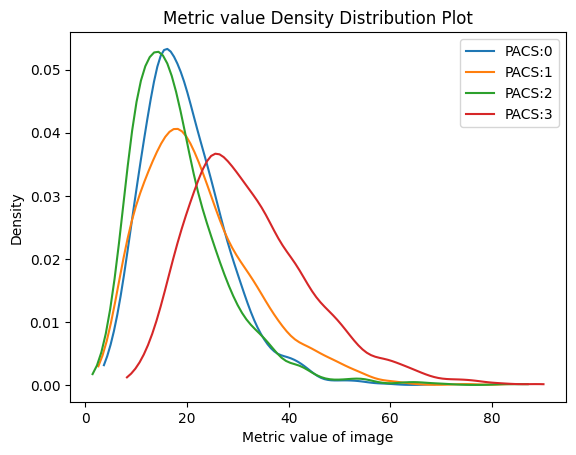

PACS


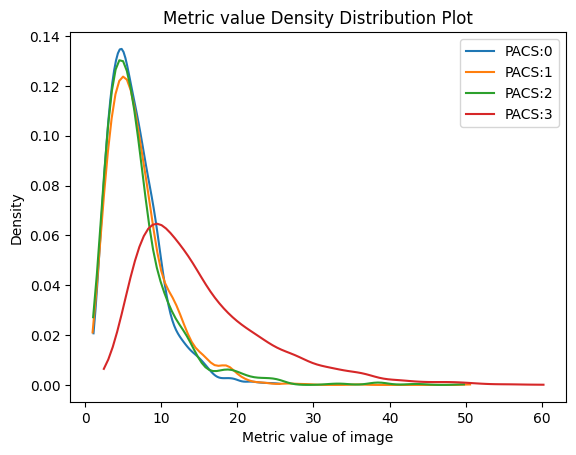

PACS


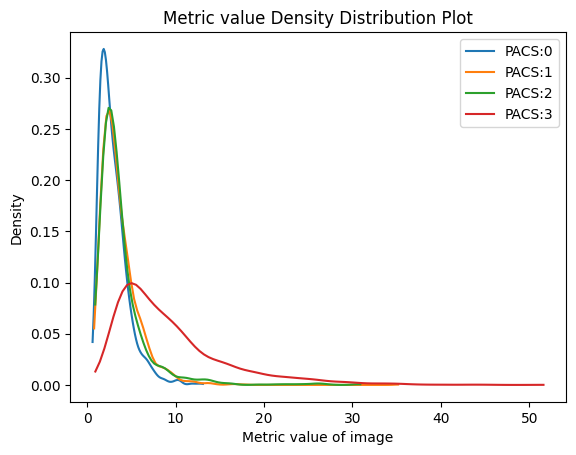

VLCS


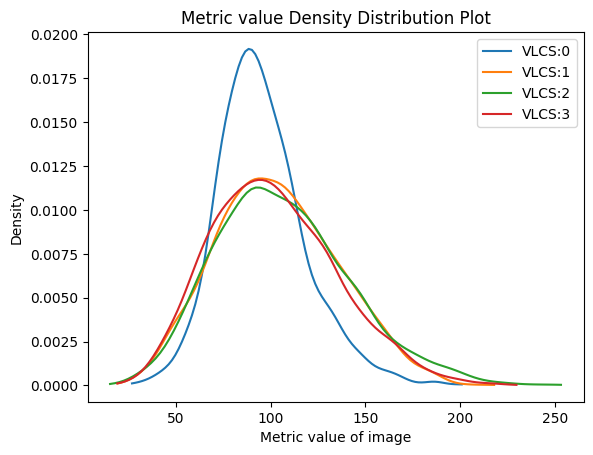

VLCS


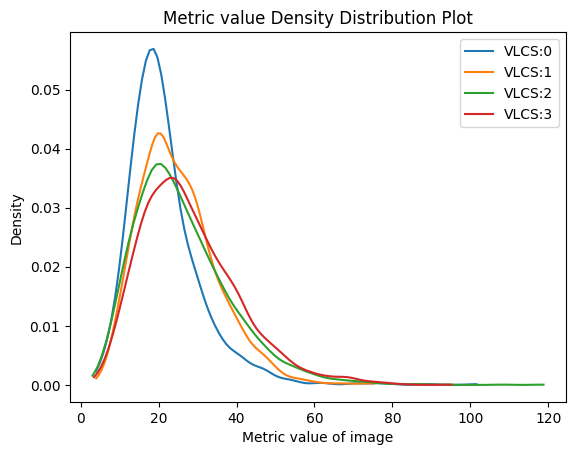

VLCS


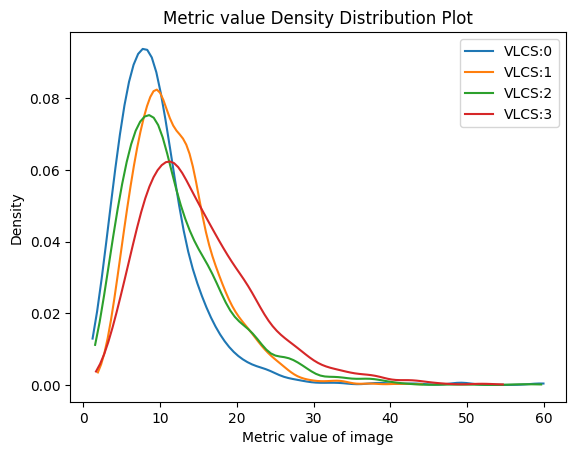

VLCS


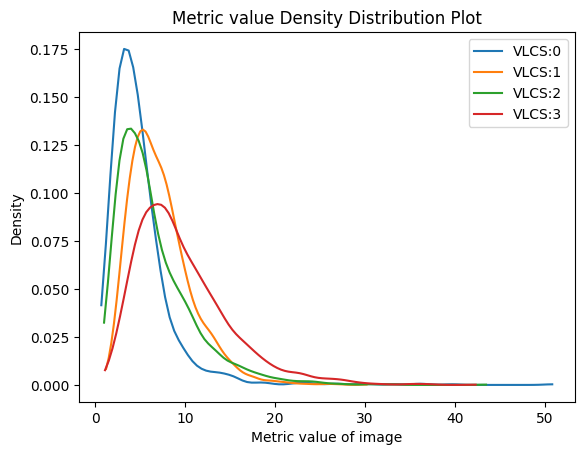

OfficeHome


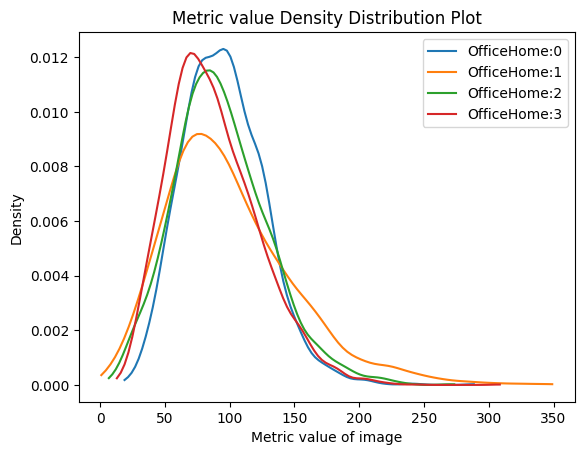

OfficeHome


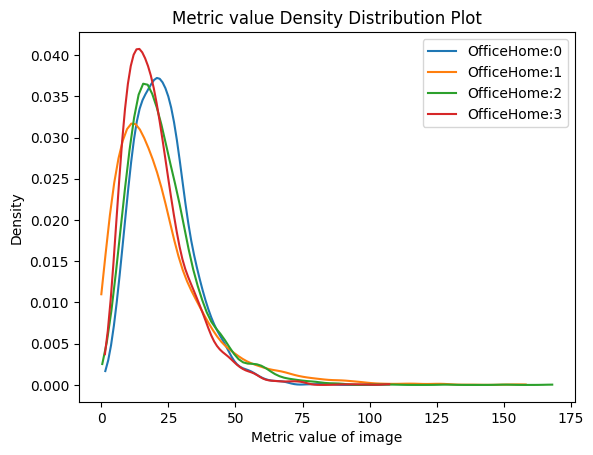

OfficeHome


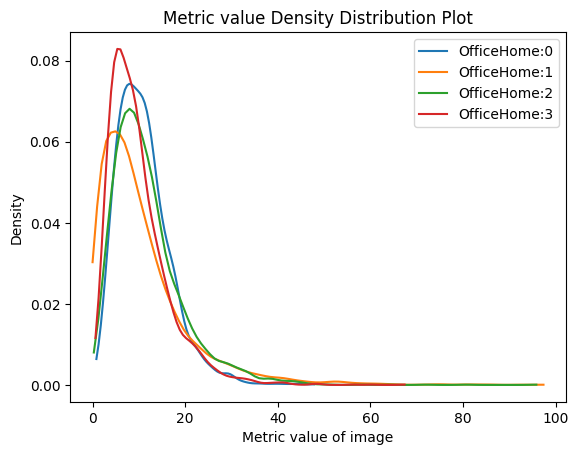

OfficeHome


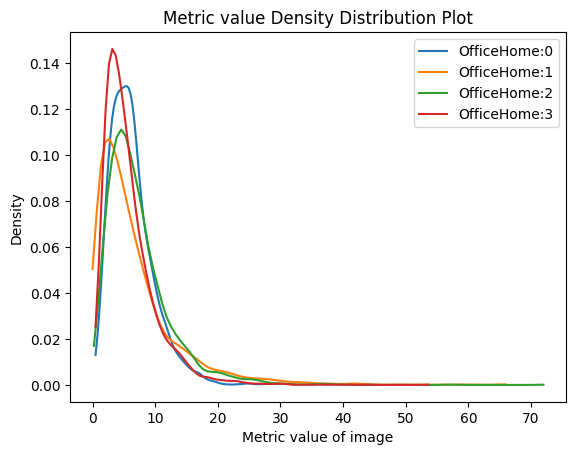

TerraIncognita


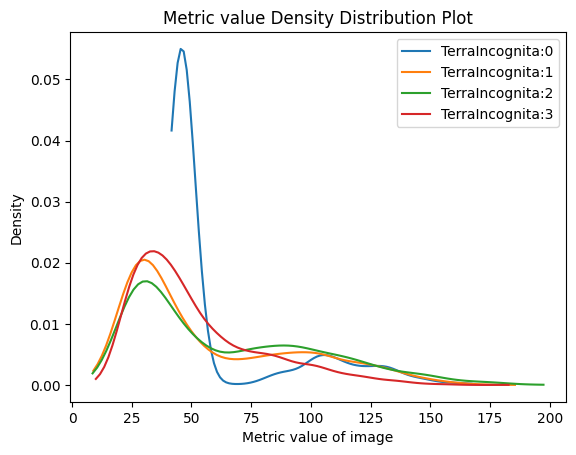

TerraIncognita


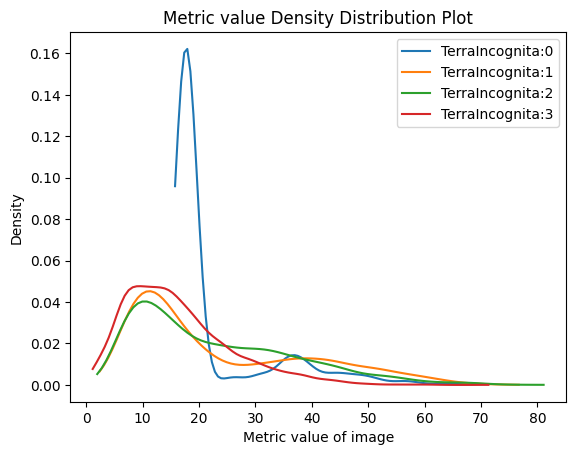

TerraIncognita


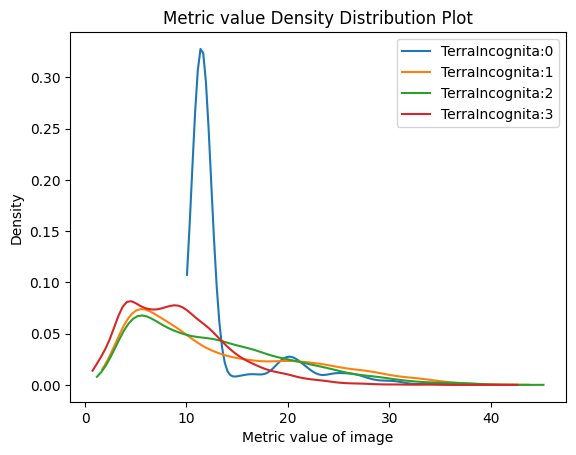

TerraIncognita


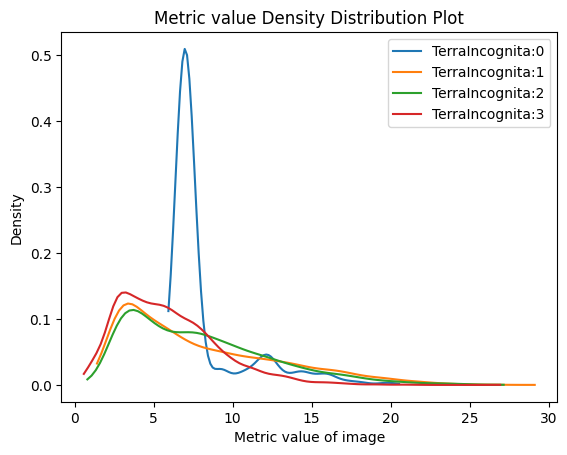

In [ ]:
# Plot density distribution curves and box plots of png values for each env in a single plot for all datasets
# dataset_list = ['PACS']
# dataset_list = ['VLCS']
# dataset_list = ['OfficeHome']
# dataset_list = ['TerraIncognita']
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']


for dataset_name in dataset_list:
    for feat_idx in range(4):
        png_values = {k:v[feat_idx].mean(dim=1).numpy() for k, v in png_values_list.items()}
        print(dataset_name)
        # filter all keys that have dataset_name in them
        dataset_keys = [key for key in png_values.keys() if dataset_name in key]

        # Get a dictionary with filtered_keys only
        dataset_png_values = {key: png_values[key] for key in dataset_keys}

        # Plot density distribution curves and box plots of png values for each env in a single plot
        get_density_values(dataset_png_values, bin_size=100, common_x_values=False, normalize=False, plot=True)

In [ ]:
png_values = get_feat_idx_dict(png_values_list, 0)
png_values

In [ ]:
# Plot density distribution curves and box plots of png values for each env in a single plot for all datasets
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot density distribution curves and box plots of png values for each env in a single plot
    get_density_values(dataset_png_values, bin_size=100, common_x_values=False, normalize=False, plot=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for all datasets
plot_heatmap(png_values, sort_flag=False, bin_size=4, common_x_values=True, normalize=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for each individual dataset
# dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

# for dataset_name in dataset_list:
#     print(dataset_name)
#     # filter all keys that have dataset_name in them
#     dataset_keys = [key for key in png_values.keys() if dataset_name in key]

#     # Get a dictionary with filtered_keys only
#     dataset_png_values = {key: png_values[key] for key in dataset_keys}

#     # Plot heatmaps of png values for each env in a single plot
#     plot_heatmap(dataset_png_values, sort_flag=False, bin_size=20, common_x_values=False, normalize=True)  

In [ ]:
# png_density_values, png_density_value_dict = get_density_values(png_values, bin_size=20, common_x_values=True, normalize=True, plot=False)
# pd.DataFrame(png_density_value_dict)

Predicted trainable blocks by Png heuristic plots

In [ ]:
# Get heuristic values for each dataset, target domain pair and store in a dictionary
heuristic_values = {}
for key in png_values.keys():
    # This key is the target domain, so all other keys are source domains
    target_png_values = png_values[key]
    source_png_values = np.concatenate([png_values[source_key] for source_key in dataset_png_values.keys() if source_key != key])

    target_heuristic_values = target_png_values / source_png_values.max()
    heuristic_values[key] = target_heuristic_values

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for all datasets
plot_heatmap(heuristic_values, sort_flag=False, bin_size=4, common_x_values=False, normalize=True)

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for each individual dataset
# dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

# for dataset_name in dataset_list:
#     print(dataset_name)
#     # filter all keys that have dataset_name in them
#     dataset_keys = [key for key in heuristic_values.keys() if dataset_name in key]

#     # Get a dictionary with filtered_keys only
#     dataset_heuristic_values = {key: heuristic_values[key] for key in dataset_keys}
    
#     # Plot heatmaps of heuristic values for each env in a single plot
#     plot_heatmap(dataset_heuristic_values, sort_flag=False, bin_size=6, common_x_values=False, normalize=True)

In [ ]:
# Evaluate mean distance between identified critical point and actual critical point for 3 granularities
print('Mean distance error for png values')
granularity_list = ['Block', 'Subblock', 'Layer']
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_dists(heuristic_values, critical_points, granularity=granularity).mean())

In [ ]:
# Evaluate mean acc improvement at identified critical point for 3 granularities
print('Mean acc improvement for png values')
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_imprvs(heuristic_values, perf_imprvs_unnorm, granularity=granularity).mean())

In [ ]:
seed = 0
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
data_dir = '/home-local2/sasah14.extra.nobkp/scratch/data'
hparams = {
    'data_augmentation': True
}
holdout_fraction = 0
batch_size = 1
test_envs = [0]

metric_dict = {}
dataset_name = 'PACS'
print("Processing dataset: {}".format(dataset_name))
if dataset_name in vars(datasets):
    dataset = vars(datasets)[dataset_name](data_dir, test_envs, hparams)
else:
    raise NotImplementedError

full_splits = []
for env_i, env in enumerate(dataset):
    _, full_split = misc.split_dataset(env, int(len(env)*holdout_fraction), misc.seed_hash(seed, env_i))
    full_split_weight = None
    full_splits.append((full_split, full_split_weight))

# Use out splits as training data (to fair comparison with train.py)
eval_loaders = [FastDataLoader(
                    dataset=env,
                    batch_size=batch_size,
                    num_workers=dataset.N_WORKERS)
                        for _, (env, _) in enumerate(full_splits)]

# eval_loader_names = ['env{}'.format(i) for i in range(len(full_splits))]
eval_loader_names = [str(i) for i in range(len(full_splits))]

In [ ]:
for name, loader in tqdm(zip(eval_loader_names, eval_loaders), total=len(eval_loaders)):
    env_metric_values = []
    for x, y in loader:
        print(x.shape)
        break
    break

In [ ]:
x.shape

In [ ]:
torch.fft.fft2(x).shape

In [ ]:
# # add gaussian noise to the image
# noise = torch.randn_like(x) * 2
# noisy_x = x + noise

In [ ]:
# # visualize the first image of the batch and the noisy image
# plt.figure(figsize=(10, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(x[0].permute(1, 2, 0))
# plt.title('Original Image')
# plt.axis('off')
# plt.subplot(1, 2, 2)
# plt.imshow(noisy_x[0].permute(1, 2, 0))
# plt.title('Noisy Image')
# plt.axis('off')
# plt.show()

In [ ]:
# print(calculate_feature_shift(x, x, extractor='fft', metric='euclidean'))
# print(calculate_feature_shift(x, noisy_x, extractor='dct', metric='euclidean'))
# print(calculate_feature_shift(x, noisy_x, extractor='dct', metric='cityblock'))
# print(calculate_feature_shift(x, noisy_x, extractor='dct', metric='canberra'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='euclidean'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='cosine'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='cityblock'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='chebyshev'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='correlation'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='canberra'))
# print(calculate_feature_shift(x, noisy_x, extractor='fft', metric='braycurtis'))

Png distribution over dataset plots

In [ ]:
png_values = get_metric_values_dict(metric_name='png')
png_values

In [ ]:
# Plot density distribution curves and box plots of png values for each env in a single plot for all datasets
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot density distribution curves and box plots of png values for each env in a single plot
    get_density_values(dataset_png_values, bin_size=100, common_x_values=False, normalize=False, plot=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for all datasets
plot_heatmap(png_values, sort_flag=True, bin_size=4, common_x_values=True, normalize=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot heatmaps of png values for each env in a single plot
    plot_heatmap(dataset_png_values, sort_flag=False, bin_size=20, common_x_values=False, normalize=True)  

In [ ]:
png_density_values, png_density_value_dict = get_density_values(png_values, bin_size=20, common_x_values=True, normalize=True, plot=False)
pd.DataFrame(png_density_value_dict)

Predicted trainable blocks by Png heuristic plots

In [ ]:
# Get heuristic values for each dataset, target domain pair and store in a dictionary
heuristic_values = {}
for key in png_values.keys():
    # This key is the target domain, so all other keys are source domains
    target_png_values = png_values[key]
    source_png_values = np.concatenate([png_values[source_key] for source_key in dataset_png_values.keys() if source_key != key])

    target_heuristic_values = target_png_values / source_png_values.max()
    heuristic_values[key] = target_heuristic_values

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for all datasets
plot_heatmap(heuristic_values, sort_flag=False, bin_size=4, common_x_values=False, normalize=True)

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in heuristic_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_heuristic_values = {key: heuristic_values[key] for key in dataset_keys}
    
    # Plot heatmaps of heuristic values for each env in a single plot
    plot_heatmap(dataset_heuristic_values, sort_flag=False, bin_size=6, common_x_values=False, normalize=True)

In [ ]:
# Evaluate mean distance between identified critical point and actual critical point for 3 granularities
print('Mean distance error for png values')
granularity_list = ['Block', 'Subblock', 'Layer']
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_dists(heuristic_values, critical_points, granularity=granularity).mean())

In [ ]:
# Evaluate mean acc improvement at identified critical point for 3 granularities
print('Mean acc improvement for png values')
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_imprvs(heuristic_values, perf_imprvs_unnorm, granularity=granularity).mean())

Jpg distribution over dataset plots

In [ ]:
png_values = get_metric_values_dict(metric_name='jpgt')
png_values

In [ ]:
# Plot density distribution curves and box plots of png values for each env in a single plot for all datasets
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot density distribution curves and box plots of png values for each env in a single plot
    get_density_values(dataset_png_values, bin_size=100, common_x_values=False, normalize=False, plot=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for all datasets
plot_heatmap(png_values, sort_flag=False, bin_size=4, common_x_values=True, normalize=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot heatmaps of png values for each env in a single plot
    plot_heatmap(dataset_png_values, sort_flag=False, bin_size=20, common_x_values=False, normalize=True)  

In [ ]:
png_density_values, png_density_value_dict = get_density_values(png_values, bin_size=20, common_x_values=True, normalize=True, plot=False)
pd.DataFrame(png_density_value_dict)

Predicted trainable blocks by Jpg heuristic plots

In [ ]:
# Get heuristic values for each dataset, target domain pair and store in a dictionary
heuristic_values = {}
for key in png_values.keys():
    # This key is the target domain, so all other keys are source domains
    target_png_values = png_values[key]
    source_png_values = np.concatenate([png_values[source_key] for source_key in dataset_png_values.keys() if source_key != key])

    target_heuristic_values = target_png_values / source_png_values.max()
    heuristic_values[key] = target_heuristic_values

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for all datasets
plot_heatmap(heuristic_values, sort_flag=False, bin_size=4, common_x_values=False, normalize=True)

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in heuristic_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_heuristic_values = {key: heuristic_values[key] for key in dataset_keys}
    
    # Plot heatmaps of heuristic values for each env in a single plot
    plot_heatmap(dataset_heuristic_values, sort_flag=False, bin_size=6, common_x_values=False, normalize=True)

In [ ]:
# Evaluate mean distance between identified critical point and actual critical point for 3 granularities
print('Mean distance error for png values')
granularity_list = ['Block', 'Subblock', 'Layer']
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_dists(heuristic_values, critical_points, granularity=granularity).mean())

In [ ]:
# Evaluate mean acc improvement at identified critical point for 3 granularities
print('Mean acc improvement for png values')
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_imprvs(heuristic_values, perf_imprvs_unnorm, granularity=granularity).mean())

fft low

In [ ]:
png_values = get_metric_values_dict(metric_name='fft_low')
png_values

In [ ]:
# Plot density distribution curves and box plots of png values for each env in a single plot for all datasets
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot density distribution curves and box plots of png values for each env in a single plot
    get_density_values(dataset_png_values, bin_size=100, common_x_values=False, normalize=False, plot=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for all datasets
plot_heatmap(png_values, sort_flag=False, bin_size=4, common_x_values=True, normalize=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot heatmaps of png values for each env in a single plot
    plot_heatmap(dataset_png_values, sort_flag=False, bin_size=20, common_x_values=False, normalize=True)  

In [ ]:
png_density_values, png_density_value_dict = get_density_values(png_values, bin_size=20, common_x_values=True, normalize=True, plot=False)
pd.DataFrame(png_density_value_dict)

Predicted trainable blocks by fft low heuristic plots

In [ ]:
# Get heuristic values for each dataset, target domain pair and store in a dictionary
heuristic_values = {}
for key in png_values.keys():
    # This key is the target domain, so all other keys are source domains
    target_png_values = png_values[key]
    source_png_values = np.concatenate([png_values[source_key] for source_key in dataset_png_values.keys() if source_key != key])

    target_heuristic_values = target_png_values / source_png_values.max()
    heuristic_values[key] = target_heuristic_values

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for all datasets
plot_heatmap(heuristic_values, sort_flag=False, bin_size=4, common_x_values=False, normalize=True)

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in heuristic_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_heuristic_values = {key: heuristic_values[key] for key in dataset_keys}
    
    # Plot heatmaps of heuristic values for each env in a single plot
    plot_heatmap(dataset_heuristic_values, sort_flag=False, bin_size=6, common_x_values=False, normalize=True)

In [ ]:
# Evaluate mean distance between identified critical point and actual critical point for 3 granularities
print('Mean distance error for png values')
granularity_list = ['Block', 'Subblock', 'Layer']
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_dists(heuristic_values, critical_points, granularity=granularity).mean())

In [ ]:
# Evaluate mean acc improvement at identified critical point for 3 granularities
print('Mean acc improvement for png values')
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_imprvs(heuristic_values, perf_imprvs_unnorm, granularity=granularity).mean())

fft_high

In [ ]:
png_values = get_metric_values_dict(metric_name='fft_high')
png_values

In [ ]:
# Plot density distribution curves and box plots of png values for each env in a single plot for all datasets
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot density distribution curves and box plots of png values for each env in a single plot
    get_density_values(dataset_png_values, bin_size=100, common_x_values=False, normalize=False, plot=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for all datasets
plot_heatmap(png_values, sort_flag=False, bin_size=4, common_x_values=True, normalize=True)

In [ ]:
# Plot density distribution based heatmap of png values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in png_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_png_values = {key: png_values[key] for key in dataset_keys}

    # Plot heatmaps of png values for each env in a single plot
    plot_heatmap(dataset_png_values, sort_flag=False, bin_size=20, common_x_values=False, normalize=True)  

In [ ]:
png_density_values, png_density_value_dict = get_density_values(png_values, bin_size=20, common_x_values=True, normalize=True, plot=False)
pd.DataFrame(png_density_value_dict)

Predicted trainable blocks by fft high heuristic plots

In [ ]:
# Get heuristic values for each dataset, target domain pair and store in a dictionary
heuristic_values = {}
for key in png_values.keys():
    # This key is the target domain, so all other keys are source domains
    target_png_values = png_values[key]
    source_png_values = np.concatenate([png_values[source_key] for source_key in dataset_png_values.keys() if source_key != key])

    target_heuristic_values = target_png_values / source_png_values.max()
    heuristic_values[key] = target_heuristic_values

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for all datasets
plot_heatmap(heuristic_values, sort_flag=False, bin_size=4, common_x_values=False, normalize=True)

In [ ]:
# Plot density distribution based heatmap of heuristic values for each env in a single plot for each individual dataset
dataset_list = ['PACS', 'VLCS', 'OfficeHome', 'TerraIncognita']

for dataset_name in dataset_list:
    print(dataset_name)
    # filter all keys that have dataset_name in them
    dataset_keys = [key for key in heuristic_values.keys() if dataset_name in key]

    # Get a dictionary with filtered_keys only
    dataset_heuristic_values = {key: heuristic_values[key] for key in dataset_keys}
    
    # Plot heatmaps of heuristic values for each env in a single plot
    plot_heatmap(dataset_heuristic_values, sort_flag=False, bin_size=6, common_x_values=False, normalize=True)

In [ ]:
# Evaluate mean distance between identified critical point and actual critical point for 3 granularities
print('Mean distance error for png values')
granularity_list = ['Block', 'Subblock', 'Layer']
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_dists(heuristic_values, critical_points, granularity=granularity).mean())

In [ ]:
# Evaluate mean acc improvement at identified critical point for 3 granularities
print('Mean acc improvement for png values')
for granularity in granularity_list:
    print(granularity, ' : ', evaluate_imprvs(heuristic_values, perf_imprvs_unnorm, granularity=granularity).mean())